# TOPIC 791 — THE AUTONOMOUS LEGAL SECOND BRAIN
### Level 3 · Endogenous Knowledge Navigation in a Synthetic Mexican Legal System

**Laboratory:** A controlled experiment in legal knowledge navigation · **Engine:** Claude Haiku 5.5 (optional) · **Dataset:** 350 entirely fictional legal notes · **Architecture:** five multiplex graph layers · **Evaluation:** three questions, three retrieval strategies.

> **LEGAL AND PEDAGOGICAL NOTICE.** Every purported statute, article, court holding, authority, legal rule, date, and legal outcome in the generated vault is **fictional**. The system does **not** reproduce or verify Mexican law, and its output must not be used for legal advice. The exercise models research methodology, not actual legal conclusions.

## Introduction — from retrieval to research judgment

A legal research system may appear knowledgeable while exercising little judgment. A semantic search engine identifies documents that resemble a question; a graph retrieval engine follows links among documents; neither operation necessarily decides what should be investigated next. This laboratory introduces a third level: an agent that can choose which legal question remains unresolved, which knowledge layer is worth exploring, and when its evidence is sufficient to prepare a qualified memorandum. Its autonomy is bounded by an auditable tool interface, evidence limits, and an explicit stopping budget.

The teaching setting is a **synthetic Mexican civil-law universe**. This choice is important. The legal research method should not imitate an exclusively precedent-centered common-law workflow. It should recognize the distinct roles of constitutional principles, primary legislation, subordinate regulation, jurisdiction and procedure, administrative interpretations, and judicial authorities. The synthetic corpus deliberately separates the formal authority of a document from its semantic similarity to the consultation. A plausible-sounding passage is not automatically applicable, and a lower-level administrative criterion does not outrank a superior legal norm. Judicial criteria are modeled with applicability and status fields, not as a simple bottom rung in a ladder.

The first level of the Second Brain series began with an Obsidian-style vault of largely independent notes. Questions were answered by selecting semantically similar material. Level 2 introduced corporate networks with navigation, ownership, and commercial relationships. There, a seed-selection component was followed by a largely parametric graph expansion: the programmer decided which paths and how many hops to traverse. The new experiment preserves the useful idea of a semantic seed but changes the subsequent behavior. An autonomous research loop is invited to reconsider its working hypothesis as evidence arrives. It can cross from a commercial question to a tax issue, from tax to customs procedure, or from administrative procedure to a constitutional guarantee when the evidence justifies the move.

The difference is subtle but fundamental. The graph is a structured repository of potential connections; the agent is a policy for choosing among them. At iteration *t*, it sees a bounded research state containing the original question, already visited notes, available neighboring documents, outstanding issues, and the remaining budget. It proposes a research action, such as visiting a specific node or stopping with a stated reason. Python validates the action and executes it. The model is never permitted to invent a node identifier, bypass the visit budget, or rewrite the underlying corpus. The state transition is recorded in a reproducible audit trail.

This laboratory deliberately tests whether the additional autonomy is beneficial. It runs three consultation scenarios against the **same** vault: a financing dispute, a customs investigation, and a cross-border acquisition. For each, it compares (A) semantic retrieval alone, (B) deterministic multi-hop graph expansion, and (C) autonomous, tool-constrained exploration. Synthetic instructor keys specify a limited set of critical source IDs and relevant domains. The experiment evaluates retrieval coverage, domain coverage, visit cost, and citation grounding. It does not equate high retrieval recall with legal correctness. A model may retrieve every key document and still misunderstand their implications; a model may also produce a persuasive but unsupported memorandum. Therefore the final report must distinguish retrieved evidence, inference, missing facts, and unresolved questions.

A further objective is operational reliability. In a classroom, an API credential may be absent, the provider may reject an argument, or a model may return malformed JSON. The notebook must continue to work as a deterministic demonstration without falsely describing its fallback as an LLM decision. When live Claude access is enabled, the notebook records which decisions were actually model-directed. When it is disabled, a deterministic heuristic operates over the same tool boundary, allowing students to inspect the mechanics and compare results. The code avoids forcing a `temperature` parameter, uses bounded prompts and response length, validates JSON defensively, and exposes the provenance of every decision.

Finally, the vault itself is an experimental instrument, not a representation of enacted law. Its 350 short notes, their metadata, and the five graph layers are created deterministically from a seed. The dataset includes relevant material, cross-domain links, distractors, fictional supersession, and exceptions. This gives the instructor an answer key and makes it possible to ask a rigorous question: *does adaptive navigation improve the acquisition of relevant evidence, relative to simple retrieval and fixed traversal, for a given research budget?* The goal is not to declare autonomy superior in advance, but to observe its behavior, costs, failure modes, and potential contribution to a more capable Second Brain.

> **Revised edition.** Google Drive root configuration is centralized in Cell 01; the Obsidian Markdown vault is exported after the graph is built in Cell 03, preserving all typed wikilinks. The Anthropic model ID can be overridden with `ANTHROPIC_MODEL`. The live model must be available to your API account; otherwise the run is explicitly labeled heuristic. Cell 15 exports auditable artifacts without rebuilding upstream objects.

## Cell 01 — Environment and reproducibility

The first code cell establishes the execution environment and the distinction between an autonomous experiment and a deterministic demonstration. A reproducible experiment requires a fixed random seed, explicit dependency versions where practical, and clear disclosure of external services. This notebook uses common Python packages available in Google Colab: NumPy, pandas, NetworkX, scikit-learn, and Matplotlib. It installs only missing dependencies. The model connector is optional. Its credential is read from Google Colab Secrets under `ANTHROPIC_API_KEY`; no credential is embedded in source or displayed in output.

Claude Haiku 5.5 is the intended judgment engine. However, an LLM is not required to construct the vault, inspect the graph, execute the baselines, or render the audit visualizations. This separation is pedagogically important. It permits students to study the architecture before activating model-directed decisions. It also prevents the notebook from becoming unusable when a service is unavailable. A configuration flag controls whether the live model is requested. The notebook then reports whether the connection is actually usable.

We avoid passing optional sampling parameters, particularly `temperature`, because API wrappers and provider versions may differ in their accepted signatures. We also bound response tokens and prompt size. If a request fails, the system does not silently claim the heuristic's output was authored by Claude. The mode is carried into the decision log and the final comparison. This matters for experimental validity: otherwise, students might mistake a deterministic walk for emergent autonomous behavior.

The reproducibility seed controls the synthetic notes, graph edges, and any heuristic tie-breaking. It cannot make an external LLM perfectly deterministic; that distinction will be stated in the results. This cell also defines the typography of tabular output and prints a compact environment summary. The output should be readable on Colab without special display infrastructure. Subsequent cells are designed to run in sequence, but each one makes its inputs explicit. We will not depend on hidden objects left behind by an earlier execution of the notebook.

In [ ]:
from IPython.display import display, Markdown
from pathlib import Path
from collections import defaultdict, Counter, deque
import sys, subprocess, importlib.util, random, re, json, math, time, os
SEED=791
random.seed(SEED)
for module, package in [('numpy','numpy'),('pandas','pandas'),('networkx','networkx'),('sklearn','scikit-learn'),('matplotlib','matplotlib')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','-q','install',package])
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
np.random.seed(SEED)
# A single authoritative root. Colab mounts Drive only when available.
DRIVE_ROOT=Path('/content/drive/MyDrive')
if importlib.util.find_spec('google.colab') is not None:
    from google.colab import drive, userdata
    if not DRIVE_ROOT.exists(): drive.mount('/content/drive')
    ROOT_DIR=DRIVE_ROOT/'Colab Notebooks'/'TOPIC_791 THE LEGAL SECOND BRAIN'
else:
    ROOT_DIR=Path.cwd()/'TOPIC_791 THE LEGAL SECOND BRAIN'
ROOT_DIR.mkdir(parents=True,exist_ok=True)
VAULT_DIR=ROOT_DIR/'vault'
VAULT_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_DIR=ROOT_DIR/'research_outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
# Preserve the instructor-selected Claude Haiku 5.5 identifier.
# If Anthropic does not recognize this identifier for your account, set
# ANTHROPIC_MODEL to the exact model ID provided by Anthropic.
# Never silently downgrade to Haiku 4.5.
MODEL=os.getenv('ANTHROPIC_MODEL','claude-haiku-5-5')
USE_CLAUDE=True
CLAUDE_ENABLED=False; claude_client=None
if USE_CLAUDE:
    try:
        key=userdata.get('ANTHROPIC_API_KEY') if importlib.util.find_spec('google.colab') is not None else os.getenv('ANTHROPIC_API_KEY')
        if key:
            if importlib.util.find_spec('anthropic') is None:
                subprocess.check_call([sys.executable,'-m','pip','-q','install','anthropic'])
            from anthropic import Anthropic
            claude_client=Anthropic(api_key=key,timeout=30.0,max_retries=1)
            CLAUDE_ENABLED=True
    except Exception as exc:
        print('Claude setup unavailable; explicitly labeled heuristic mode:',type(exc).__name__)
print({'root':str(ROOT_DIR),'model':MODEL,'live_client_configured':CLAUDE_ENABLED,'seed':SEED})

Mounted at /content/drive
{'root': '/content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN', 'model': 'claude-haiku-5-5', 'live_client_configured': True, 'seed': 791}


## Cell 02 — Generate the synthetic legal vault

A complex Second Brain needs more than a collection of disconnected paragraphs. Each note must carry information that can support multiple forms of navigation: legal domain, normative category, institutional provenance, synthetic authority status, topics, and references to other notes. We will generate exactly 350 short documents. Their distribution spans constitutional, civil, commercial, criminal, tax, administrative, securities, customs, international, and jurisprudential domains. Each note receives a stable identifier that can be cited throughout the experiment.

The content is intentionally compact. A legal note describes a fictional proposition, an issue trigger, a possible exception or condition, and a related domain. This is enough to make retrieval and cross-domain traversal meaningful without consuming excessive model context. The notes are not copied from real statutes or judicial decisions. Even where the text uses familiar Mexican legal terminology, the articles and rules are invented for the exercise. The `synthetic=True` field travels with every record so that downstream components cannot accidentally present the material as verified law.

The generator introduces several kinds of research difficulty. Some notes concern the same topic but belong to different domains. Others are plausible distractors. Some are marked as subject to an exception or supersession. The key is that textual similarity, legal applicability, and formal authority are separate attributes. A semantic retriever may find a document with excellent lexical overlap that is not controlling. A graph explorer may encounter an administrative note whose applicability depends on a higher-level rule. An autonomous agent should be able to notice such problems and adjust its search.

The corpus is designed for classroom use rather than doctrinal realism. It is not possible to guarantee substantive legal accuracy from a synthetic rule generator, and we do not attempt to do so. Instead, we require internal consistency, visible metadata, and a hidden instructor key for each consultation. The notes will later be connected by five relationship layers. Importantly, we will construct the dataset only once and use the identical vault in all experimental arms. That prevents changes in corpus composition from masquerading as improvements in research strategy.

In [ ]:
from pathlib import Path
import os
import json

DOMAIN_COUNTS = {'Constitutional':25,'Civil':40,'Commercial':45,'Criminal':35,'Tax':45,'Administrative':35,'Securities':35,'Customs':25,'International':30,'Jurisprudence':35}
assert sum(DOMAIN_COUNTS.values()) == 350
TOPICS = ['financing','investor disclosure','corporate governance','import classification','customs declaration','tax assessment','due process','contractual breach','cross-border acquisition','foreign investor','administrative sanction','beneficial ownership','evidence preservation','appeal','jurisdiction','fiduciary duty','share transfer','criminal intent','treaty coordination','regulatory filing']
TYPES = {'Constitutional':'constitutional principle','Jurisprudence':'judicial interpretive criterion','Administrative':'administrative rule','Securities':'sectoral regulation','Customs':'sectoral regulation','International':'international instrument'}
notes = {}; domain_ids = defaultdict(list)
for domain, count in DOMAIN_COUNTS.items():
    for i in range(1,count+1):
        nid=f'{domain[:3].upper()}-{i:03d}'
        primary=TOPICS[(i*3+len(domain))%len(TOPICS)]
        secondary=TOPICS[(i*7+len(domain))%len(TOPICS)]
        status='superseded' if i%19==0 else ('exception-sensitive' if i%11==0 else 'illustrative-current')
        kind=TYPES.get(domain,'fictional statutory provision')
        text=(f'FICTIONAL TRAINING DOCUMENT {nid}. In the synthetic {domain.lower()} domain, the illustrative {kind} addresses {primary} and {secondary}. '
              f'An examiner must establish the relevant facts, competent authority, and applicability conditions before relying on this note. '
              f'Where {primary} overlaps another domain, a cross-domain check is required. Status: {status}. '
              'This invented rule has no force in Mexico and must never be cited as enacted law.')
        notes[nid]={'id':nid,'domain':domain,'type':kind,'topics':[primary,secondary], 'status':status,'text':text,'synthetic':True}
        domain_ids[domain].append(nid)
assert len(notes)==350 and all(n['synthetic'] for n in notes.values())

# Save the canonical JSON corpus once, using the configured root.
VAULT_JSON=ROOT_DIR/'TOPIC_791_SYNTHETIC_VAULT.json'
VAULT_JSON.write_text(json.dumps(notes,indent=2,ensure_ascii=False),encoding='utf-8')
print('Synthetic notes:',len(notes),'JSON:',VAULT_JSON)
display(pd.DataFrame(notes.values())[['id','domain','type','status','topics']].head(12))

Synthetic notes: 350 JSON: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/TOPIC_791_SYNTHETIC_VAULT.json


,id,domain,type,status,topics
0,CON-001,Constitutional,constitutional principle,illustrative-current,"[criminal intent, investor disclosure]"
1,CON-002,Constitutional,constitutional principle,illustrative-current,"[financing, cross-border acquisition]"
2,CON-003,Constitutional,constitutional principle,illustrative-current,"[import classification, fiduciary duty]"
3,CON-004,Constitutional,constitutional principle,illustrative-current,"[due process, corporate governance]"
4,CON-005,Constitutional,constitutional principle,illustrative-current,"[foreign investor, foreign investor]"
5,CON-006,Constitutional,constitutional principle,illustrative-current,"[evidence preservation, share transfer]"
6,CON-007,Constitutional,constitutional principle,illustrative-current,"[fiduciary duty, import classification]"
7,CON-008,Constitutional,constitutional principle,illustrative-current,"[treaty coordination, administrative sanction]"
8,CON-009,Constitutional,constitutional principle,illustrative-current,"[investor disclosure, criminal intent]"
9,CON-010,Constitutional,constitutional principle,illustrative-current,"[customs declaration, customs declaration]"


## Cell 03 — Build five multiplex relationship graphs

A legal research vault becomes genuinely interconnected when a document can participate in several distinct relationship systems. A single contract note may be linked to another contract by substantive similarity, to a tax note by transactional consequence, to an administrative note by a procedural requirement, and to a constitutional principle by a due-process question. Treating all these connections as one undifferentiated edge would erase important information about why a path was followed.

We therefore create five graph layers. The normative hierarchy layer connects notes to higher-order principles and implementing rules. The substantive layer links obligations and legal issues. The interpretation layer represents the relevance of synthetic judicial criteria. The procedural layer captures authority, filing, remedy, and process connections. The cross-border layer joins international, customs, securities, tax, and commercial topics. Each edge stores its relationship label. These are **navigation links**, not declarations of legal priority or verified legal applicability.

For computational simplicity, the notebook uses one NetworkX multigraph. Multiple edges can connect the same two notes under different layers, and the edge attribute records the layer. This permits us to ask both broad questions—what documents are neighbors of this note?—and focused questions—what procedural links emerge from it? A graph summary will report edge counts by layer and verify that every edge endpoint exists in the vault. Students should observe that a graph can be dense without being equally informative for every consultation.

We create within-domain links to ensure local coherence, then cross-domain links that represent plausible research transitions. Constitutional notes connect to multiple sectors, but are not forced into every search path. Jurisprudence connects to interpretive targets; international and customs materials connect to transactions with cross-border dimensions. The graph is deterministic under the fixed seed. It is intentionally richer than the two or three prongs of the previous laboratory, but it remains small enough to visualize and traverse interactively in Colab.

The architectural point is that edges are **opportunities to investigate**, not commands to follow. The baseline traversal will follow a fixed policy, while the autonomous agent will be asked to select among neighboring candidates using the question and accumulated evidence. This separation between representation and policy is the essential design innovation of Level 3.

In [ ]:
LAYERS=['hierarchy','substantive','interpretation','procedure','cross_border']
G=nx.MultiGraph(); G.add_nodes_from(notes)
for domain, ids in domain_ids.items():
    for j, a in enumerate(ids):
        G.add_edge(a,ids[(j+1)%len(ids)],layer='substantive')
        if j+3<len(ids): G.add_edge(a,ids[j+3],layer='procedure')
for domain, ids in domain_ids.items():
    if domain!='Constitutional':
        for j, a in enumerate(ids):
            if j%3==0: G.add_edge(a,domain_ids['Constitutional'][j%25],layer='hierarchy')
            if j%4==0: G.add_edge(a,domain_ids['Jurisprudence'][(j+len(domain))%35],layer='interpretation')
for j in range(170):
    a=list(notes)[(j*17+9)%350]
    b=list(notes)[(j*31+47)%350]
    if a!=b: G.add_edge(a,b,layer='substantive')
for a_domain,b_domain in [('Commercial','Securities'),('Commercial','Tax'),('Tax','Customs'),('Customs','International'),('International','Securities'),('Administrative','Criminal'),('Civil','Commercial'),('Securities','Administrative'),('Tax','Administrative')]:
    for j in range(16):
        a=domain_ids[a_domain][(j*3)%len(domain_ids[a_domain])]
        b=domain_ids[b_domain][(j*5)%len(domain_ids[b_domain])]
        layer='cross_border' if 'International' in (a_domain,b_domain) or 'Customs' in (a_domain,b_domain) else 'procedure'
        G.add_edge(a,b,layer=layer)
assert G.number_of_nodes()==350 and all(u in notes and v in notes for u,v in G.edges())
print('Nodes:',G.number_of_nodes(),'Edges:',G.number_of_edges())
print('Layers:',dict(Counter(d['layer'] for _,_,d in G.edges(data=True))))

# Obsidian export is deliberately AFTER graph construction so wikilinks are complete.
# Stable filenames, YAML arrays, and layer-specific link sections.

MANIFEST={}
for nid,doc in notes.items():
    links=defaultdict(list)
    for other,edge_map in G.adj[nid].items():
        for attrs in edge_map.values(): links[attrs['layer']].append(other)
    front={'id':nid,'domain':doc['domain'],'type':doc['type'],
           'status':doc['status'],'topics':doc['topics'],'synthetic':True,
           'tags':['synthetic-law','topic-791',doc['domain'].lower()]}
    sections=['---',"\n".join(f"{k}: {json.dumps(v,ensure_ascii=False)}" for k,v in front.items()),'---',
              '',f'# {nid} — {doc["domain"]}','', '> FICTIONAL TRAINING MATERIAL — NOT MEXICAN LAW','',
              '## Synthetic provision','',doc['text'],'']
    for layer in LAYERS:
        related=sorted(set(links.get(layer,[])))
        if related: sections.extend([f'## {layer.replace("_"," ").title()} links','',
                                     ', '.join(f'[[{other}]]' for other in related),''])
    target=VAULT_DIR/f'{nid}.md'
    target.write_text('\n'.join(sections).rstrip()+'\n',encoding='utf-8')
    MANIFEST[nid]={'file':target.name,'linked_nodes':len(set(G.neighbors(nid)))}
assert len(MANIFEST)==350
assert all((VAULT_DIR/f'{nid}.md').exists() for nid in notes)
assert any('[[CON-' in p.read_text(encoding='utf-8') for p in VAULT_DIR.glob('*.md'))
(ROOT_DIR/'vault_manifest.json').write_text(json.dumps(MANIFEST,indent=2),encoding='utf-8')
print('Obsidian-ready vault:',VAULT_DIR,'notes:',len(MANIFEST),'graph edges:',G.number_of_edges())

Nodes: 350 Edges: 1180
Layers: {'substantive': 520, 'procedure': 416, 'hierarchy': 111, 'interpretation': 85, 'cross_border': 48}
Obsidian-ready vault: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/vault notes: 350 graph edges: 1180


## Cell 04 — Retrieval and bounded navigation tools

The autonomous agent should not be allowed to manipulate the vault directly. Instead, it must use a small, inspectable tool interface. This cell constructs a TF-IDF index and provides functions for semantic search, node inspection, and graph-neighbor discovery. Each function returns only a bounded amount of information. The tool boundary is a governance mechanism: it prevents unbounded context accumulation, unauthorized data mutation, and fabricated citations to nonexistent notes.

Semantic search is useful for initial orientation. Given a consultation, it ranks notes by lexical and phrase similarity, returning stable identifiers and scores. Its limitations are equally important. A note can be semantically similar without being legally applicable. A crucial procedural exception may use very different words from the initial question. For that reason, semantic search is only one tool in the research process, not the entire process. The graph allows the system to discover related notes that would not have been retrieved by text similarity alone.

The neighbor tool reports candidate documents, their domains, and the relationship layers that connect them to an already visited node. It does not return every edge in the vault. Candidate ranking combines the relevance of a note to the consultation with the fact that it is adjacent to current evidence. This is a practical compromise between comprehensive exploration and bounded inference costs. A student can inspect the same candidate list the agent receives and ask whether the selected next step is defensible.

The tool design also makes auditing possible. Each visited note has a stable ID; each proposed visit can be validated against a finite set of offered candidates; each citation can be checked against the visited evidence set. In a real legal system, one would additionally need source authentication, versioning, official publication provenance, temporal applicability, and formal validation of jurisdiction. Our synthetic metadata gestures toward these concepts but does not replace real legal research controls.

Finally, we keep the agent's information asymmetrical. It can discover neighbors and inspect evidence, but it does not receive the instructor's hidden answer key. The evaluator may use that key after the research run. This prevents the experiment from simply telling the agent which documents to retrieve and then crediting it for finding them.

In [ ]:
ids=list(notes)
vectorizer=TfidfVectorizer(ngram_range=(1,2),stop_words='english',max_features=6000)
X=vectorizer.fit_transform([notes[n]['text']+' '+' '.join(notes[n]['topics']) for n in ids])
ID_TO_ROW={nid:i for i,nid in enumerate(ids)}
def scores_for(query):
    return cosine_similarity(vectorizer.transform([query]),X).ravel()
def semantic_search(query,k=8):
    scores=scores_for(query)
    return [{'id':ids[i],'score':round(float(scores[i]),4),'domain':notes[ids[i]]['domain']} for i in np.argsort(-scores)[:k]]
def inspect_node(nid):
    if nid not in notes: raise KeyError('Unknown synthetic document ID')
    return dict(notes[nid])
def neighbor_candidates(visited,query,k=12):
    scores=scores_for(query); candidates={}
    for nid in visited:
        for other,edge_map in G.adj[nid].items():
            if other in visited: continue
            layers=sorted({attr['layer'] for attr in edge_map.values()})
            item=candidates.setdefault(other,{'id':other,'domain':notes[other]['domain'],'layers':set(),'score':float(scores[ID_TO_ROW[other]])})
            item['layers'].update(layers)
    ranked=sorted(candidates.values(),key=lambda z:(-z['score'],-len(z['layers']),z['id']))[:k]
    return [{**z,'layers':sorted(z['layers']),'score':round(z['score'],4)} for z in ranked]
print('Example seeds:',semantic_search('financing investor disclosure contractual breach',5))

Example seeds: [{'id': 'CUS-020', 'score': 0.5442, 'domain': 'Customs'}, {'id': 'CRI-013', 'score': 0.413, 'domain': 'Criminal'}, {'id': 'TAX-008', 'score': 0.4117, 'domain': 'Tax'}, {'id': 'TAX-028', 'score': 0.4108, 'domain': 'Tax'}, {'id': 'CIV-014', 'score': 0.4091, 'domain': 'Civil'}]


### Researcher Perspective: How I Use These Navigation Tools

Imagine I am your dedicated legal researcher. You have handed me a massive library of 350 fictional legal documents (the **Vault**) and given me a **Research Question**. To do my job without getting overwhelmed or distracted, I use the four specialized tools defined above in Cell 4 as my navigation setup:

1. **My Search Assistant (`semantic_search`)**:
   When you first hand me a case, I don't know where to start. I use this tool to quickly find the top 8 documents that sound most similar to your question. These act as my initial "clues" or **seeds**.

2. **My Document Reader (`inspect_node`)**:
   Once I have a document ID (like `CON-001`), I can't just guess what's inside it. I use this tool to pull up its full text, checking its domain, its topics, and whether it has any warning flags (such as being superseded).

3. **My Map Explorer (`neighbor_candidates`)**:
   This is where the magic happens. After reading my current documents, I don't want to just run search queries forever. I look at the physical connections (the web/graph) branching out from the documents I have already visited. This tool lists the neighboring documents linked by relationships (like procedural or tax implications) and ranks them so I can choose the most logical path to follow next.

4. **My Focus Mechanism (`scores_for`)**:
   Behind the scenes, this calculates how closely any document matches your original problem, ensuring that as I explore the web of links, I stay focused on your specific case and don't wander off into unrelated legal domains.

### The Research Cycle: Evaluating, Branching, and Pruning

To understand how I navigate once I reach the "neighbors" phase, think of my process as a **dynamic loop** rather than a blind, ever-growing tree. Here is how I manage the search without getting lost in the forest:

1. **I Look at the "Frontier" (The Neighbors)**:
   I don't just look at the neighbors of *one* document. My **Frontier** is the combined pool of all neighbors connected to *any* of the documents I have already visited.

2. **I Evaluate Relevance dynamically (`scores_for`)**:
   Before I take a single step, I look at every neighbor in that combined pool and ask: *"How close is this to the original user question?"* and *"What layer of connection brought us here (tax, procedure, etc.)?"*

3. **I Decisively Choose, I Do Not Uncontrollably Grow (Pruning)**:
   Instead of visiting every branch (which would create an massive, unmanageable tree), **I prune the tree implicitly**. Every turn, I only choose the single highest-scoring, most promising candidate from the frontier to read next. The other, low-scoring neighbors are temporarily set aside or "pruned" from my active attention.

4. **I Jump Back and Across (No Hop Limits)**:
   Because I choose from the *entire* frontier, I am not locked into going deeper and deeper down one rabbit hole (like a fixed chain of neighbor-of-neighbor-of-neighbor). If I go down a procedural branch and it turns out to be a dead-end with low relevance scores, **I instantly pivot**. I can jump back and pick a highly relevant tax neighbor connected to my very first seed.

5. **I Stop When the Evidence is Sufficient**:
   At each step, I ask myself: *"Do I have enough solid pieces of evidence to write the memorandum, or am I just finding repetitive information?"* If I am satisfied, or if I have exhausted my budget, I call a halt.

In short: I build a map of possible paths (the graph), but I only walk the path that continuously proves its relevance to your original problem, discarding the weak links along the way.

## Cell 05 — Three consultations and instructor evaluation keys

To study navigation, we need consultations that differ in their legal trajectory but share the same repository. The first concerns financing and investor representations. The second concerns imported equipment and an administrative customs investigation. The third concerns an international acquisition with corporate, tax, securities, and cross-border dimensions. These are synthetic fact patterns. They are designed to force the researcher to decide whether additional legal domains are relevant, not to elicit an actual Mexican legal opinion.

Each scenario includes a question, expected research domains, and a small instructor-defined set of critical source identifiers. The critical sources are chosen deterministically from the generated corpus, with an emphasis on semantic relevance inside the intended domains. This is a **synthetic retrieval benchmark**, not a gold-standard legal analysis. The key can measure whether the researcher discovered important notes, but it cannot by itself prove that the legal reasoning is sound. We will therefore report coverage and groundedness separately from substantive legal correctness.

The evaluation key must not be passed into the live agent prompt. If the agent were told the target source IDs, navigation would cease to be an independent discovery problem. The key is used only after each method completes. We can compare how many target notes were found, how many intended domains were represented, and how many documents were inspected to achieve that coverage. A high score obtained by visiting nearly the entire vault may be less impressive than similar coverage with a disciplined research budget.

The consultations also invite attention to facts not provided. For instance, whether a securities regime applies may depend on the financing instrument and offering circumstances; whether an administrative action is challengeable may depend on notice and procedural posture. The agent should not invent these facts. Instead, the final memorandum should identify factual dependencies and unresolved issues. This is particularly important for a legal audience: a research agent that always produces a confident answer is not necessarily a good research agent.

Students should also examine whether the graph architecture introduces biases. A dense constitutional hub may be visited too often. A highly connected tax note may attract traversal despite weak factual relevance. A semantic index may overemphasize repeated terminology. These are features of the experiment, not incidental implementation details. The later comparison should be read as evidence about this synthetic design, not as a general proof that one legal research method always dominates another.

In [ ]:
CASES={
 'A_Financing':{'question':'A Mexican company financed by a foreign investor faces alleged misleading investor disclosure and contractual breach. Investigate securities, commercial, tax, administrative and constitutional issues.','domains':['Commercial','Securities','Tax','Administrative','Constitutional']},
 'B_Customs':{'question':'Imported equipment is disputed in a customs declaration and tax assessment. Investigate customs classification, tax, administrative procedure, possible criminal intent and due process.','domains':['Customs','Tax','Administrative','Criminal','Constitutional']},
 'C_Acquisition':{'question':'A foreign investor proposes a cross-border corporate acquisition with share transfer, financing and regulatory filing. Investigate commercial, international, securities, tax and civil issues.','domains':['Commercial','International','Securities','Tax','Civil']}
}
for case in CASES.values():
    sc=scores_for(case['question'])
    case['critical_ids']=[max(domain_ids[d],key=lambda nid:sc[ID_TO_ROW[nid]]) for d in case['domains']]
for name,case in CASES.items():
    print(name,'| expected domains:',', '.join(case['domains']),'| hidden key size:',len(case['critical_ids']))
print('Instructor keys remain in CASES but are never supplied to the agent decision function.')

A_Financing | expected domains: Commercial, Securities, Tax, Administrative, Constitutional | hidden key size: 5
B_Customs | expected domains: Customs, Tax, Administrative, Criminal, Constitutional | hidden key size: 5
C_Acquisition | expected domains: Commercial, International, Securities, Tax, Civil | hidden key size: 5
Instructor keys remain in CASES but are never supplied to the agent decision function.


### Researcher Perspective: Deconstructing Cell 5 and Case Structure
Cell 5 is where our structured scenario benchmarks (the **Cases**) are defined, analyzed, and prepared for evaluation. Here is exactly what happens under the hood:

1. **The Case Structure (The "Problem Definition")**:
   Each case is submitted with two explicit pieces of information:
   * **`question`**: A rich, realistic text scenario detailing a legal problem (e.g., an imported equipment dispute with customs).
   * **`domains`**: An initial list of expected legal areas that a human expert knows will be relevant (such as *Customs*, *Tax*, *Criminal*, etc.).

2. **The Ground Truth Generation (The "Hidden Key")**:
   Once a case is defined, the system performs a quick, deterministic calculation behind the scenes:
   * It runs our vectorizer's scoring system (`scores_for`) against the case's question.
   * For each expected legal domain, it finds the **single document in the database with the absolute highest relevance score** within that specific domain.
   * This group of documents becomes the **`critical_ids`** (or the instructor's hidden answer key).

3. **Why is this hidden?**:
   Just like in a real-world test, we keep these `critical_ids` locked away in the `CASES` dictionary. The Researcher Agent is **never** given this list of target IDs. It is only given the raw `question`.

4. **The Evaluation Goal**:
   We use this hidden key afterward to grade how well our research methods (whether they are simple keyword searches, fixed graph traversals, or your advanced AI agent) managed to discover these crucial documents. It allows us to measure *efficiency*—did the researcher find the key needle in the haystack without reading all 350 documents?

## Cell 06 — Baselines: semantic and fixed traversal

A meaningful autonomy claim requires a comparison group. Our first baseline is pure semantic retrieval: select a fixed number of documents with the highest similarity to the consultation. This method has no memory of research gaps, no explicit knowledge of relationship types, and no ability to change direction after finding a new clue. Its strength is simplicity, speed, and reproducibility. Its weakness is that it may miss documents whose wording is unlike the initial question.

The second baseline reproduces the essential spirit of Level 2. It selects semantic seeds, then follows graph neighbors according to a deterministic breadth-first traversal with a fixed depth and visit limit. This method recognizes interconnections, but its exploration policy is exogenous. It does not ask whether a newly discovered tax issue deserves more attention than a marginal commercial issue. It simply applies the programmed expansion rule. We deliberately keep its budget comparable to the autonomous method so that results are not dominated by the number of inspected notes.

Both baselines produce a set of visited document IDs and a navigation trace. The trace is crucial. We do not merely want a final answer; we want to know *how* evidence was acquired. Students should be able to observe that semantic retrieval jumps directly to notes across domains, while fixed traversal follows graph adjacency. In the next cells, the agent will follow a third pattern: select candidates in response to emerging gaps and evidence.

The comparison will use the same initial question, corpus, vectorizer, graph, and evaluation key. The baselines will not be granted access to information withheld from the agent, and the agent will not be granted access to the answer key. The methods will differ only in their navigation policies and the amount of computational reasoning required. Because model calls have monetary and latency costs, the experiment will also record their count rather than treating autonomy as free.

One caution is necessary: our graph and critical sources are synthetically generated, so the benchmark may favor the specific ways in which documents were connected. We should not interpret one notebook run as a statistically robust result. Rather, this is a controlled classroom experiment that exposes the mechanisms. A more rigorous research project would repeat the experiment across multiple corpus seeds, case variants, model settings, and expert-annotated legal benchmarks.

In [ ]:
def semantic_baseline(question,budget=18):
    path=[x['id'] for x in semantic_search(question,budget)]
    return {'path':path,'visited':set(path),'mode':'semantic','trace':[{'step':i+1,'node':n,'reason':'semantic rank'} for i,n in enumerate(path)],'llm_calls':0}
def fixed_baseline(question,budget=18,depth=3):
    seeds=[x['id'] for x in semantic_search(question,3)]
    seen=set(seeds); path=list(seeds); queue=deque((s,0) for s in seeds)
    while queue and len(path)<budget:
        nid,h=queue.popleft()
        if h>=depth: continue
        for nxt in sorted(G.neighbors(nid)):
            if nxt not in seen:
                seen.add(nxt);path.append(nxt);queue.append((nxt,h+1))
                if len(path)>=budget: break
    return {'path':path,'visited':set(path),'mode':'fixed','trace':[{'step':i+1,'node':n,'reason':'fixed graph expansion'} for i,n in enumerate(path)],'llm_calls':0}
BASELINES={name:{'semantic':semantic_baseline(c['question']),'fixed':fixed_baseline(c['question'])} for name,c in CASES.items()}
print(pd.DataFrame([{'case':name,'method':m,'documents':len(run['visited'])} for name,methods in BASELINES.items() for m,run in methods.items()]))

            case    method  documents
0    A_Financing  semantic         18
1    A_Financing     fixed         18
2      B_Customs  semantic         18
3      B_Customs     fixed         18
4  C_Acquisition  semantic         18
5  C_Acquisition     fixed         18


### Researcher Perspective: Understanding the Cell 6 Baselines as "Rigid" Context Builders

Cell 6 is where we build our control group—our **baselines**—and they do not use an LLM, intelligence, or adaptive judgment. Instead, they build context using rigid, parametric, and mathematical rules:

1. **The Semantic Baseline (A Purely Mathematical Context)**:
   * **How it works**: It takes the original user question, calculates its vector embedding, and retrieves the top 18 documents with the highest mathematical similarity.
   * **The structure**: It is completely flat and static. There is no concept of a graph, no following links, and no memory. It assumes that if a document doesn't explicitly share similar vocabulary with your question, it must not be relevant (even if it is highly relevant on a deeper conceptual or procedural level).

2. **The Fixed Traversal Baseline (A Rigidly Programmed Search)**:
   * **How it works**: It starts with just 3 semantic seeds. Then, like a machine, it blindly grabs all of their direct neighbors. Next, it grabs those neighbors' neighbors, continuing until it hits its exact "budget" limit of 18 documents.
   * **The structure**: This is highly structural but completely *blind*. It follows connections, but it cannot prioritize. If it lands on an irrelevant document, it will still explore all of that document's neighbors with the same priority as a highly relevant document.

### Why are we doing this?
These two methods show us what happens when we build a context envelope using **pure parameters** (like a fixed budget of 18 or a fixed depth of 3) without any active decision-making. By comparing them to our final autonomous agent, we can prove whether adding an LLM's judgment actually helps us find more critical documents with a smaller, cleaner, and cheaper research budget.

## Cell 07 — Research Initialization

Welcome to the starting block of our autonomous agent! Cell 7 acts as the "launchpad" where we prepare our researcher agent to tackle a new case. Before we let the agent navigate on its own, we must provide it with an initial setup, a set of preliminary assumptions, and a map of where to start looking. This initialization is done through the `initialize_research` function.

First, the function gathers **three initial seeds**. It does this by executing a quick semantic search using the case's core question. Think of these seeds as our starting clues—the most mathematically obvious documents in the vault. They give the researcher an immediate foothold in the corpus.

Second, we construct the **research state** dictionary. This tracks everything about our ongoing investigation in real time. It stores:
*   The original **question**.
*   The set of **visited** document IDs (initialized with our three seeds) so we never waste time reading the same document twice.
*   A sequential **path** (the chronological order of our journey).
*   An initial checklist of **issues** to investigate (e.g., "Check potential customs implications"), derived directly from the first three expected legal domains of the case.
*   An audit **trace** that logs exactly why we visited each node (starting with "semantic seed" as the reason).
*   Metrics to monitor our resource consumption, such as **llm_calls** and any execution **errors**.

Finally, the code loops through our benchmark cases, initializes their states, and prints out our starting point: the three seed document IDs and the size of our initial **frontier** (the number of adjacent neighboring documents connected to our seeds). This frontier represents the immediate branching paths available for our agent to explore in the very next step.

In [ ]:
def initialize_research(case):
    seeds=[r['id'] for r in semantic_search(case['question'],3)]
    return {'question':case['question'],'visited':set(seeds),'path':list(seeds),'seeds':seeds,
            'issues':[f'Check potential {d.lower()} implications' for d in case['domains'][:3]],
            'trace':[{'step':0,'node':s,'reason':'semantic seed','source':'retriever'} for s in seeds],
            'llm_calls':0,'errors':[],'mode':'pending'}
for name,c in CASES.items():
    st=initialize_research(c)
    print(name,'seeds:',st['seeds'],'frontier:',len(neighbor_candidates(st['visited'],st['question'],12)))

A_Financing seeds: ['COM-013', 'SEC-013', 'COM-017'] frontier: 12
B_Customs seeds: ['ADM-010', 'ADM-030', 'COM-005'] frontier: 12
C_Acquisition seeds: ['CUS-007', 'INT-021', 'INT-001'] frontier: 12


### Researcher Perspective: Understanding the "Frontier" and Helper Functions in Cell 7

Two crucial concepts come together in the output of Cell 7:

#### 1. What does "frontier: 12" mean?
When we say **frontier**, we are talking about the "borderline" of our current knowledge. At the very beginning of our search, we are handed **3 seed documents** (our starting points).

*   These 3 seed documents are connected to other documents in the database by legal relationship links (the graph).
*   The **frontier** is the combined pool of all unique documents that are exactly *one hop away* (direct neighbors) from any of our 3 seeds.
*   In this specific run, each case starts with a frontier of **exactly 12 unique neighboring documents**. These 12 documents represent the immediate legal paths available for the researcher to explore next.

#### 2. How are we using the Cell 4 Helper Functions here?
Cell 7 directly utilizes the helper tools we defined earlier to construct this initial research state:

*   **`semantic_search(..., k=3)`**: The initialization function calls this tool first to grab the initial 3 seed documents based purely on text similarity to the case's question.
*   **`neighbor_candidates(visited, question, k=12)`**: To print the frontier size, we pass our set of `visited` seeds to this tool. Under the hood, this function finds all adjacent neighbors of our seeds, calculates their relevance scores using **`scores_for`**, and returns the top 12 candidates. This tells us exactly how many viable steps are ready for exploration right at the starting line.

## Cell 08 — Autonomous research agent and governed stopping

This is the central laboratory cell. In Level 2, graph expansion was decided by code: choose a predetermined set of relationship types and traverse a fixed number of hops. In Level 3, the LLM is asked to select the next navigation action from an explicit candidate frontier. It receives the consultation, short summaries of visited evidence, outstanding issues, and a finite list of candidate nodes with domain and relationship metadata. It must return a structured decision: visit one offered node, or stop with a reason. Python validates the action before executing it.

This is **bounded autonomy**, not unrestricted access. The agent cannot invent a source, change the corpus, execute arbitrary Python, or exceed the research budget. A stopping decision is permitted only after a minimum number of visits; a hard maximum remains in place regardless of model preference. These are safety and cost controls. The important change is that the *direction* and *distribution* of exploration are no longer determined by a fixed depth parameter. The LLM can choose to remain in a domain, cross to another domain, or stop based on the evolving evidence state.

The prompt emphasizes evidence acquisition rather than legal conclusion. It asks which unresolved issue would benefit most from the next available document. It also instructs the model not to treat the synthetic notes as real Mexican law. The response parser accepts JSON objects, tolerates fenced output, and validates the `action` and `node_id` against the actual candidate list. If the model fails or returns an invalid decision, a deterministic heuristic chooses a candidate and labels the action as a fallback. The audit trail records the requested mode, executed mode, node, reason, and any error.

The heuristic fallback is not meant to impersonate Claude. It uses semantic relevance plus a modest novelty bonus for domains not yet visited. This allows the notebook to demonstrate the loop without credentials. But the pedagogical claim about endogenous LLM judgment applies only to iterations genuinely directed by the live model. The final comparison will report how many such decisions occurred. Students can inspect the decision log to distinguish a research agent from a fixed graph algorithm.

Stopping deserves special attention. A model can stop because it believes it has enough evidence, because no candidates remain, or because a hard budget has been reached. These are not equivalent. The notebook records the stopping reason and does not translate budget exhaustion into a claim of legal completeness. A legal research memorandum should state what remains unresolved and what facts or authoritative sources would still be needed before real-world reliance. The core lesson is that autonomous exploration is valuable only when paired with verifiable boundaries and an honest account of uncertainty.

In [ ]:
def parse_decision(raw):
    raw=raw.strip()
    match=re.search(r'```(?:json)?\s*(.*?)```',raw,re.S|re.I)
    if match: raw=match.group(1).strip()
    try: return json.loads(raw)
    except json.JSONDecodeError:
        start=raw.find('{'); end=raw.rfind('}')
        if start>=0 and end>start: return json.loads(raw[start:end+1])
        raise

def heuristic_choice(frontier,visited):
    domains={notes[n]['domain'] for n in visited}
    ranked=sorted(frontier,key=lambda z:-(z['score']+0.08*(z['domain'] not in domains)+0.01*len(z['layers'])))
    return {'action':'visit','node_id':ranked[0]['id'],'reason':'heuristic relevance, domain novelty, and graph connectivity'}

def model_choice(question,visited,frontier,issues):
    context=[{'id':n,'domain':notes[n]['domain'],'topics':notes[n]['topics'],'status':notes[n]['status']} for n in visited[-10:]]
    payload={'question':question,'visited_evidence':context,'open_issues':issues[:6], 'candidate_frontier':frontier}
    system=('You are a research NAVIGATION planner over entirely FICTIONAL legal documents, not a legal adviser. '
            'Choose only one offered candidate node ID or stop. Seek missing relevant domains and exceptions. '
            'Do not invent sources. Return only JSON: {"action":"visit"|"stop","node_id":string|null,"reason":string}.')
    msg=claude_client.messages.create(model=MODEL,max_tokens=350,system=system,
        messages=[{'role':'user','content':json.dumps(payload,ensure_ascii=False)}])
    raw=''.join(getattr(part,'text','') for part in msg.content)
    return parse_decision(raw)

def autonomous_run(case,budget=18,min_visits=7,max_llm_calls=15):
    st=initialize_research(case); stop_reason='budget exhausted'
    if budget < len(st['path']): raise ValueError('Budget must allow initial seeds')
    while len(st['visited'])<budget:
        frontier=neighbor_candidates(st['visited'],st['question'],k=15)
        if not frontier: stop_reason='frontier exhausted'; break
        decision=None; source='heuristic'
        if CLAUDE_ENABLED and st['llm_calls']<max_llm_calls:
            st['llm_calls']+=1
            try:
                decision=model_choice(st['question'],st['path'],frontier,st['issues'])
                source='claude'
            except Exception as exc:
                st['errors'].append(type(exc).__name__+': '+str(exc)[:150])
        offered={z['id'] for z in frontier}
        if not isinstance(decision,dict) or decision.get('action') not in ('visit','stop') or (decision.get('action')=='visit' and decision.get('node_id') not in offered):
            decision=heuristic_choice(frontier,st['visited']); source='heuristic_fallback' if CLAUDE_ENABLED else 'heuristic'
        if decision['action']=='stop':
            if len(st['visited'])>=min_visits:
                stop_reason='agent requested stop: '+str(decision.get('reason',''))[:120]; break
            decision=heuristic_choice(frontier,st['visited']);source='minimum-evidence fallback'
        nid=decision['node_id'];st['visited'].add(nid);st['path'].append(nid)
        st['trace'].append({'step':len(st['path']),'node':nid,'reason':str(decision.get('reason',''))[:220],'source':source,'domain':notes[nid]['domain']})
    st['mode']='live_llm' if any(t.get('source')=='claude' for t in st['trace']) else 'heuristic_only'
    if CLAUDE_ENABLED and st['llm_calls']>=max_llm_calls and stop_reason=='budget exhausted':
        stop_reason='budget exhausted (LLM call cap reached; fallback decisions labeled)'
    st['stop_reason']=stop_reason
    return st
AGENT_RUNS={name:autonomous_run(c) for name,c in CASES.items()}
for name,run in AGENT_RUNS.items():
    print(name,{'mode':run['mode'],'visited':len(run['visited']),'llm_calls':run['llm_calls'],'stop':run['stop_reason'],'errors':run['errors'][:2]})

A_Financing {'mode': 'live_llm', 'visited': 18, 'llm_calls': 15, 'stop': 'budget exhausted (LLM call cap reached; fallback decisions labeled)', 'errors': ['JSONDecodeError: Expecting value: line 1 column 1 (char 0)', 'JSONDecodeError: Expecting value: line 1 column 1 (char 0)']}
B_Customs {'mode': 'live_llm', 'visited': 18, 'llm_calls': 15, 'stop': 'budget exhausted (LLM call cap reached; fallback decisions labeled)', 'errors': ['JSONDecodeError: Unterminated string starting at: line 1 column 48 (char 47)', 'JSONDecodeError: Unterminated string starting at: line 1 column 48 (char 47)']}
C_Acquisition {'mode': 'live_llm', 'visited': 18, 'llm_calls': 15, 'stop': 'budget exhausted (LLM call cap reached; fallback decisions labeled)', 'errors': ['JSONDecodeError: Expecting value: line 1 column 1 (char 0)', 'JSONDecodeError: Unterminated string starting at: line 1 column 48 (char 47)']}


### Researcher Perspective: Inside Cell 8 (The Autonomous Agent and Bounded Autonomy)

Cell 8 is the "brain" of the entire workflow. This is where we transition from rigid, programmed path-following to an active, decision-making agent. Let's break down how this agent works, how it compares to our baselines, and how it uses our Cell 4 tools:

#### 1. The Dynamic Search Process vs. The Baselines
Unlike our baselines in Cell 6, which are entirely automatic and parametric, our autonomous agent behaves like an active human researcher:
* **The Baselines** simply grab the top 18 semantic matches or blindly crawl 18 neighbor links regardless of relevance.
* **The Agent (`autonomous_run`)** moves one step at a time. In each turn, it looks at its current history, evaluates a dynamic list of neighboring documents (the **frontier**), and makes an intelligent decision: *"Which specific document should I read next to address my outstanding checklist issues?"* It can switch domains, double-back, or zoom in on high-value targets.

#### 2. How the LLM Decides to Stop
To prevent the agent from searching forever (which would waste API keys and budget), we enforce **Bounded Autonomy** through a governed stopping mechanism:
* **Agent Request (`"action": "stop"`)**: When the LLM believes it has collected enough facts to address all issues, it can output a JSON command to `stop`.
* **Min-Visits Safeguard**: The code checks the LLM's stopping request. If the agent tries to stop *before* it has visited at least `min_visits` (7) documents, the system overrides its decision and forces a fallback step to ensure thorough research.
* **Hard Budget Cap**: If the agent keeps searching without stopping, the outer loop will forcefully stop the process once it hits our budget limit (e.g., 18 visited documents) or a cap on LLM calls.

#### 3. How Cell 8 Integrates with Cell 4 Tools
This entire loop relies on the helper functions we defined in Cell 4 to feed data to and execute decisions for the LLM:
* **`neighbor_candidates`**: At the start of each iteration, we pass our set of `visited` documents to this tool to generate the top 15 candidate nodes representing the frontier. This restricts the LLM's choices to **only valid, existing, connected documents** (preventing hallucination).
* **`scores_for`**: Behind the scenes, the candidate list generated by `neighbor_candidates` is pre-sorted using relevance scores computed by this function. This guarantees the LLM is always choosing from the absolute best available options.
* **`inspect_node` (Conceptually)**: The payload sent to the LLM (`visited_evidence`) extracts document metadata (domain, topics, and status) similar to how we inspect nodes to give the LLM clear context on what it has already learned.

### Researcher Perspective: Evaluation and Decision-Making in the LLM Prompt

When we look closely at how the LLM evaluates information and makes decisions in Cell 8, a key question arises: **Does the agent directly see or consider the numerical scores computed by our helper functions?**

#### 1. How the Agent Views the Scores
**No, the LLM is not directly shown the raw numerical relevance scores.**
* The helper function `neighbor_candidates` uses `scores_for` to calculate scores behind the scenes, but before presenting the `candidate_frontier` list to the LLM, the raw numeric scores are stripped or hidden.
* Instead, the system **pre-sorts** the candidate list in descending order of relevance before handing it to the model. The LLM receives the candidates implicitly ranked by quality, which guides its focus without cluttering the prompt with raw floating-point numbers.

#### 2. How the Prompt Models the Evaluation Process
The prompt instructs the agent to make its decision through qualitative, systematic reasoning rather than mathematical calculations. It models the decision process using three distinct pillars:

* **Matching Outstanding Issues to the Frontier**: The model is given a list of `open_issues` (e.g., "Check potential customs implications"). It evaluates the candidate nodes by looking at their `domain` and `topics` metadata to decide which document is most likely to resolve one of these active issues.
* **Expanding Missing Domains**: The agent is prompted to seek missing relevant domains and check for exceptions. If it sees that a crucial domain listed in the original case is completely unrepresented in its `visited_evidence` history, it will prioritize candidate nodes from that missing domain.
* **Strict Verification of Source IDs**: To enforce control and prevent hallucination, the prompt strictly dictates that the model can *only* choose a node ID that is explicitly present inside the provided `candidate_frontier` array, or output a stop command. It is not allowed to write freeform document names.

### Researcher Agent's System Instructions (Cell 8)

In the `model_choice` function of **Cell 8**, the LLM is configured with a strict, targeted `system` prompt that defines its persona, objectives, inputs, and constraints. Here is the exact string defined in the code:

```python
system = (
    'You are a research NAVIGATION planner over entirely FICTIONAL legal documents, not a legal adviser. '
    'Choose only one offered candidate node ID or stop. Seek missing relevant domains and exceptions. '
    'Do not invent sources. Return only JSON: {"action":"visit"|"stop","node_id":string|null,"reason":string}.'
)
```

### How This Instruction Governs Behavior and Inputs:

1. **Role & Boundaries**: It tells the model it is a **navigation planner** over **fictional** documents, preventing it from trying to give actual legal advice or treating the synthetic notes as real law.
2. **Decision Action**: It restricts its choices to either choosing *one* candidate from the offered list or declaring a `stop`.
3. **Search Goal**: It instructs the model to seek out missing domains (domains expected by the case but not yet visited) and hunt down exceptions.
4. **Anti-Hallucination**: It explicitly forbids inventing sources (`Do not invent sources`).
5. **Output Schema**: It strictly demands a single JSON response conforming to a specific payload structure: `{"action": "...", "node_id": "...", "reason": "..."}`.

### Researcher Perspective: Seeding vs. Searching (Who Builds the Candidates?)

Who Builds the Candidates in Cell 8?
In Cell 8, during each step of the autonomous run, **Python builds the candidates, while the LLM chooses from them.**
* At the start of every loop iteration, the Python controller runs `neighbor_candidates(st['visited'], st['question'], k=15)`.
* This helper function mathematically scans the database, looks at all links connected to already visited documents, ranks them using vector search (`scores_for`), and serves up the top 15 candidates.
* **The LLM does not generate this list.** The list is handed to the LLM on a silver platter.

**Why This Division of Labor Matters**
We do this to enforce **verifiable boundaries** on our agent:
* If the LLM were allowed to build its own candidate lists (i.e. if it acted as its own seeding or discovery engine), it would inevitably hallucinate fictitious document IDs (like `TAX-999` or `CON-123`) that do not exist in the database.
* By keeping candidate generation **deterministic (handled by Python)** and candidate selection **autonomous (handled by the LLM)**, we ensure the agent can only walk along real paths that physically exist inside our 350-document database. The LLM is strictly a decision-maker, not an indexing engine.

### Researcher Perspective: What Happens After a Candidate is Chosen?

Once the LLM selects a candidate node ID from the provided list, the system enters the next phase of its sequential exploration loop. Here is exactly how that choice is processed and how the search continues:

#### 1. Integration into the Active State
When the LLM outputs the chosen ID (e.g., `"node_id": "TAX-104"`), the Python controller performs the following immediate state updates:
* **Appends to Path**: The selected ID is appended to `st['path']` (the ordered list tracking the exact journey of our research).
* **Adds to Visited Set**: The selected ID is added to the Python set `st['visited']`. This is critical because it ensures that this document is marked as "read" and cannot be suggested to the LLM as a candidate in any future iteration.
* **Logs Audit Trace**: The choice, the reasoning provided by the LLM, the source of the decision (`'claude'`), and the document's domain are appended to `st['trace']` for evaluation and visualization in Cell 10.

#### 2. Re-seeding and Re-ranking the Frontier
In the very next iteration of the loop, the newly visited document acts as an updated "seed" for expansion:
* Python calls `neighbor_candidates(st['visited'], st['question'], k=15)` again.
* Because our visited set now includes this newly selected node, **the underlying search graph expands**. The function dynamically scans the outgoing and incoming links of *all* visited documents (including the one just chosen) to construct a fresh frontier of 15 candidate nodes.
* These new candidates are mathematically ranked using `scores_for`, filtering out any documents that have already been read.

#### 3. Loop Termination
This process of **evaluate frontier → choose candidate → update state → generate new frontier** repeats sequentially, step-by-step, until one of three terminal events occurs:
1. **LLM Stop Request**: The LLM determines all checklist issues are resolved and outputs `"action": "stop"` (subject to the `min_visits` fallback safeguard).
2. **Budget Exhaustion**: The total number of visited documents reaches the designated hard limit (e.g., 18 steps).
3. **Frontier Exhaustion**: There are no remaining unvisited neighbors connected to the research path.

## Cell 09 — Evidence-grounded synthetic legal memorandum

A research path is not yet a legal memorandum. After collecting documents, the system must organize the evidence into issues, relevant sources, limitations, and next steps. The distinction between research and writing matters: an agent can navigate well but still overstate its conclusions. In this laboratory, the memorandum generator is deliberately conservative. It assembles a structured summary from the visited synthetic notes and checks every cited identifier against the evidence set. It does not claim that any fictional rule is binding law.

The memorandum begins with the consultation and the method used to acquire evidence. It then lists the domains actually represented in the retrieved set, identifies a small number of relevant documents, and flags any sources marked as superseded or exception-sensitive. Those flags do not decide legal applicability, but they remind the student that retrieval alone is not enough. A legally careful researcher must verify the status, temporal applicability, and authority of each source before relying on it. For a synthetic exercise, we can model these checks; for real practice, official sources and professional review would be indispensable.

We also include explicit missing-facts and research-limitation sections. In the financing case, for example, the classification of the financing instrument may be decisive. In the customs case, the exact declaration and procedural stage may matter. In the acquisition case, transaction structure and parties' legal status may change the analysis. The notebook should not invent such details. Its proper output is a map of research findings and unresolved dependencies, not a false claim of definitive legal advice.

To make the demonstration reproducible and safe without credentials, this cell uses deterministic report composition. A future extension could employ Claude to draft prose from the validated evidence package, but that would require a second structured generation boundary and explicit post-generation citation checks. We avoid mixing the navigation experiment with an unmeasured writing model in the first version. This keeps the source of improvements identifiable: if the agent's memorandum contains more relevant evidence, it is because its research path found different documents, not because a separate prose model embellished the answer.

The output therefore resembles an evidence inventory with legal-research headings. It is sufficient to demonstrate how an autonomous Second Brain turns navigation into an auditable work product. Students should read it critically and compare it with the underlying notes. The most important quality standard is not elegance of language, but the ability to trace every substantive statement to a source and distinguish that source from an inference or unanswered question.

In [ ]:
def compose_memo(name,case,run):
    visited=list(run['path']); domains=sorted({notes[n]['domain'] for n in visited})
    flags=[n for n in visited if notes[n]['status']!='illustrative-current']
    lines=[f'# SYNTHETIC RESEARCH MEMORANDUM — {name}',
           '**Training material only. No actual Mexican legal rule is represented.**',
           '\n## Consultation\n'+case['question'],
           '\n## Research method\n'+run['mode']+'; '+str(len(visited))+' inspected synthetic documents; stop: '+run.get('stop_reason','not applicable'),
           '\n## Domains investigated\n'+', '.join(domains),
           '\n## Selected evidence (fictional source identifiers)']
    for nid in visited[:12]:
        n=notes[nid];lines.append(f'- **[{nid}]** {n["domain"]}: {", ".join(n["topics"])}. Status: {n["status"]}.')
    lines+=['\n## Applicability cautions',
            f'{len(flags)} inspected documents carry synthetic exception or supersession flags; verify before treating any proposition as applicable.',
            '\n## Missing facts and required human review',
            'Confirm transaction facts, jurisdiction, dates, actual source authority, procedural posture, and current official texts before any real-world legal conclusion.',
            '\n## Scope disclaimer',
            'This is an invented educational corpus. Neither the documents nor this memorandum constitute legal advice.']
    memo='\n'.join(lines)
    cited=set(re.findall(r'\[([A-Z]{3}-\d{3})\]',memo))
    assert cited <= run['visited'], 'Citation outside visited evidence set'
    return memo
MEMOS={name:compose_memo(name,c,AGENT_RUNS[name]) for name,c in CASES.items()}
from IPython.display import display, Markdown
display(Markdown(MEMOS['A_Financing']))

# SYNTHETIC RESEARCH MEMORANDUM — A_Financing
**Training material only. No actual Mexican legal rule is represented.**

## Consultation
A Mexican company financed by a foreign investor faces alleged misleading investor disclosure and contractual breach. Investigate securities, commercial, tax, administrative and constitutional issues.

## Research method
live_llm; 18 inspected synthetic documents; stop: budget exhausted (LLM call cap reached; fallback decisions labeled)

## Domains investigated
Administrative, Civil, Commercial, Constitutional, Criminal, Customs, International, Jurisprudence, Securities, Tax

## Selected evidence (fictional source identifiers)
- **[COM-013]** Commercial: foreign investor, investor disclosure. Status: illustrative-current.
- **[SEC-013]** Securities: foreign investor, investor disclosure. Status: illustrative-current.
- **[COM-017]** Commercial: investor disclosure, foreign investor. Status: illustrative-current.
- **[ADM-021]** Administrative: criminal intent, investor disclosure. Status: illustrative-current.
- **[TAX-034]** Tax: tax assessment, investor disclosure. Status: illustrative-current.
- **[CON-009]** Constitutional: investor disclosure, criminal intent. Status: illustrative-current.
- **[CIV-034]** Civil: contractual breach, import classification. Status: illustrative-current.
- **[CUS-006]** Customs: tax assessment, foreign investor. Status: illustrative-current.
- **[ADM-011]** Administrative: contractual breach, beneficial ownership. Status: exception-sensitive.
- **[JUR-016]** Jurisprudence: investor disclosure, tax assessment. Status: illustrative-current.
- **[TAX-028]** Tax: contractual breach, regulatory filing. Status: illustrative-current.
- **[CRI-017]** Criminal: regulatory filing, contractual breach. Status: illustrative-current.

## Applicability cautions
4 inspected documents carry synthetic exception or supersession flags; verify before treating any proposition as applicable.

## Missing facts and required human review
Confirm transaction facts, jurisdiction, dates, actual source authority, procedural posture, and current official texts before any real-world legal conclusion.

## Scope disclaimer
This is an invented educational corpus. Neither the documents nor this memorandum constitute legal advice.

## Cell 10 — Evaluation, audit and navigation visualization

The final cell turns the laboratory into an experiment. We compare the three navigation policies on the same questions and instructor keys. The main metrics are critical-source recall, expected-domain coverage, number of documents inspected, and model-call count. We also inspect the agent's audit trail and plot its path through legal domains. These measures are deliberately limited: they describe evidence acquisition in a synthetic environment, not the quality of a real legal opinion.

Critical-source recall is the proportion of instructor-selected note IDs found by a method. Domain coverage is the proportion of expected domains represented among the visited notes. These metrics answer different questions. A method may touch all five domains while missing the most important document in each; another may retrieve all key sources but consume a disproportionate research budget. The comparison table makes such tradeoffs visible. The agent's model-call count adds a practical cost dimension, especially when using a live API.

The navigation visualization should help students see whether autonomy actually changes behavior. We plot the sequence of visited domains for the agent and provide a compact audit table with decision source and reason. A deterministic fallback trace is still useful, but it must not be described as LLM reasoning. When Claude is available, students can read the model's stated rationale for each move. That rationale is an explanation supplied by the model, not proof of its internal reasoning process; the actual verifiable behavior is the chosen tool action and the evidence returned.

The experiment is designed to support both success and failure. If autonomous navigation improves coverage, students should ask whether the gain justifies the extra calls and complexity. If it performs worse, students should inspect the frontier ranking, stopping decision, prompt constraints, and graph construction. Perhaps a relevant document was never offered as a candidate; perhaps the model overvalued a constitutional hub; perhaps the synthetic benchmark rewarded lexical overlap rather than meaningful cross-domain investigation. Each failure can become a lesson in system architecture.

We conclude by distinguishing three levels of achievement. Level 1 answers questions from retrieved notes. Level 2 exploits known relationships between notes. Level 3 chooses new evidence-gathering actions as the investigation evolves. The next level would introduce specialized legal research agents that challenge each other's issue spotting, citations, and interpretations under an explicit governance framework. Before building that multi-agent extension, students should be able to demonstrate that this single-agent loop is transparent, bounded, reproducible where possible, and honest about uncertainty. That is the standard of a responsible autonomous Second Brain.

,case,method,critical_recall,domain_coverage,documents,llm_calls,execution_mode
0,A_Financing,semantic,1.0,1.0,18,0,semantic
1,A_Financing,fixed,0.4,1.0,18,0,fixed
2,A_Financing,agent,0.4,1.0,18,15,live_llm
3,B_Customs,semantic,0.8,0.8,18,0,semantic
4,B_Customs,fixed,0.4,0.6,18,0,fixed
5,B_Customs,agent,0.8,0.8,18,15,live_llm
6,C_Acquisition,semantic,0.4,0.4,18,0,semantic
7,C_Acquisition,fixed,0.4,0.4,18,0,fixed
8,C_Acquisition,agent,0.8,1.0,18,15,live_llm


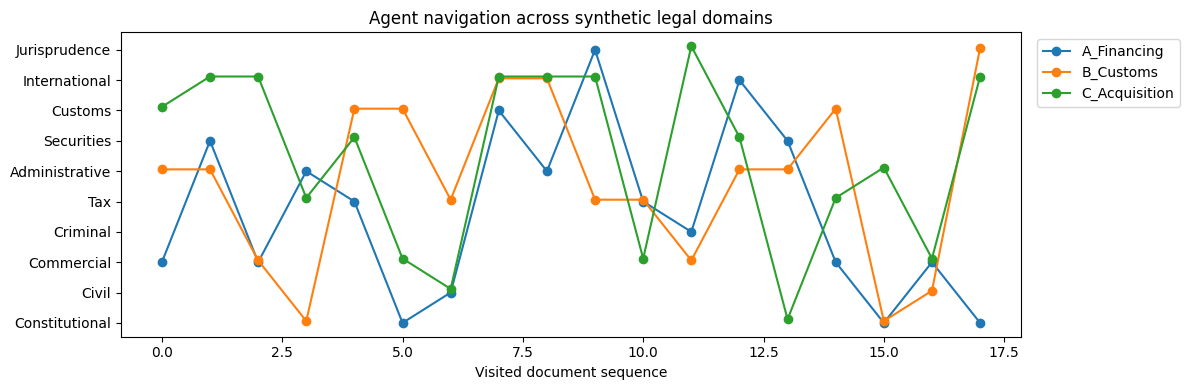

AUDIT TRACE — FINANCING


,step,node,reason,source,domain
3,4,ADM-021,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Administrative
4,5,TAX-034,"No tax-domain evidence has been visited yet, a...",claude,Tax
5,6,CON-009,The question explicitly asks for constitutiona...,claude,Constitutional
6,7,CIV-034,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Civil
7,8,CUS-006,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Customs
8,9,ADM-011,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Administrative
9,10,JUR-016,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Jurisprudence
10,11,TAX-028,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Tax
11,12,CRI-017,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,Criminal
12,13,INT-028,"heuristic relevance, domain novelty, and graph...",heuristic_fallback,International


Interpretation: these scores evaluate synthetic evidence retrieval, not legal correctness.


In [ ]:
def metrics(case,run):
    target=set(case['critical_ids']); expected=set(case['domains']); seen=run['visited']
    return {'critical_recall':len(target&seen)/len(target),
            'domain_coverage':len(expected&{notes[n]['domain'] for n in seen})/len(expected),
            'documents':len(seen),'llm_calls':run.get('llm_calls',0)}
rows=[]
for name,case in CASES.items():
    for method,run in {**BASELINES[name],'agent':AGENT_RUNS[name]}.items():
        rows.append({'case':name,'method':method,**metrics(case,run),'execution_mode':run['mode']})
results=pd.DataFrame(rows)
display(results.round(3))
fig,ax=plt.subplots(figsize=(12,4))
for i,(name,run) in enumerate(AGENT_RUNS.items()):
    dom=[notes[n]['domain'] for n in run['path']]
    unique=list(DOMAIN_COUNTS)
    y=[unique.index(d) for d in dom]
    ax.plot(range(len(y)),[z+i*0.06 for z in y],marker='o',linewidth=1.5,label=name)
ax.set_yticks(range(len(DOMAIN_COUNTS)),list(DOMAIN_COUNTS))
ax.set_xlabel('Visited document sequence');ax.set_title('Agent navigation across synthetic legal domains')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1));plt.tight_layout();plt.show()
print('AUDIT TRACE — FINANCING')
display(pd.DataFrame(AGENT_RUNS['A_Financing']['trace']).tail(15))
print('Interpretation: these scores evaluate synthetic evidence retrieval, not legal correctness.')

## Cell 11 — Provenance, authority and temporal applicability

A sophisticated legal research system must distinguish discovering a document from determining whether the document is legally applicable. A search result may be semantically relevant yet obsolete, subject to an exception, or associated with an authority that has no competence over the matter. This cell builds an explicit provenance and applicability register from the fictional metadata in the vault. Its purpose is methodological: to prevent a research agent from confusing textual similarity with normative force. The synthetic documents are not enacted Mexican law; their labels are deliberately invented and must never be passed off as official sources.

The first operation assembles a reproducible register containing each note's identifier, domain, source type, synthetic status and illustrative validity status. The second operation defines a gate that separates the act of citing a document from the stronger act of relying on it as support for a conclusion. A superseded note is treated as unsuitable for positive support; an exception-sensitive note requires an additional applicability check; a current illustrative note is usable only within the fictional exercise. These decisions are explicit, testable and open to instructor inspection.

The cell then reviews the autonomous runs already produced in Cell 8. For each consultation, it counts potentially usable notes, exception-sensitive notes and superseded notes, displaying the results as a compact table. This is not a substitute for a Mexican-law hierarchy analysis. In a real system, one would need official publication dates, effective dates, competent issuing bodies, amendments, transitory provisions, jurisdictional scope, and the binding status of judicial criteria. Such attributes are absent from this fictional vault and should not be hallucinated.

Pedagogically, the exercise makes a central point: evidence acquisition and authority validation are different operations. A capable agent may navigate broadly but must refrain from presenting an unverified source as controlling law. This register is also the beginning of a governance layer: it gives students a concrete example of how deterministic validation can constrain generative judgment without removing the agent's ability to decide what to investigate next.

In [ ]:
PROVENANCE = pd.DataFrame([{'id':n['id'],'domain':n['domain'],'source_type':n['type'],
 'status':n['status'],'synthetic':n['synthetic']} for n in notes.values()]).set_index('id')
def authority_gate(nid):
    n=notes[nid]
    if not n['synthetic']: raise ValueError('This laboratory accepts only fictional training records')
    if n['status']=='superseded': return 'exclude_from_positive_support'
    if n['status']=='exception-sensitive': return 'needs_applicability_review'
    return 'illustrative_only'
provenance_rows=[]
for name,run in AGENT_RUNS.items():
    counts=Counter(authority_gate(nid) for nid in run['path'])
    provenance_rows.append({'case':name,**{k:counts[k] for k in
        ['illustrative_only','needs_applicability_review','exclude_from_positive_support']}})
display(pd.DataFrame(provenance_rows))
assert len(PROVENANCE)==350 and PROVENANCE.synthetic.all()
print('Authority gates defined; no fictional note is represented as enacted Mexican law.')

,case,illustrative_only,needs_applicability_review,exclude_from_positive_support
0,A_Financing,14,4,0
1,B_Customs,16,2,0
2,C_Acquisition,14,4,0


Authority gates defined; no fictional note is represented as enacted Mexican law.


## Cell 12 — Research sufficiency and auditable stopping

The central claim of Level 3 is that navigation becomes endogenous: the research agent may decide what to explore and when to stop. This capability introduces a new failure mode. A model may terminate its search because it feels confident, because its context has become repetitive, or because it has reached an arbitrary token limit. None of these is evidence that the legal investigation is complete. This cell therefore separates a proposed stop from an auditable sufficiency assessment.

We construct a diagnostic using information available to the experiment's evaluator: the number of documents inspected, the diversity of legal domains reached, the presence of exception or supersession flags, and the recorded stopping reason. These quantities are useful but limited. Domain diversity is not synonymous with relevance, and a large number of retrieved notes does not imply a sound legal answer. Accordingly, the diagnostic produces an explicit checklist rather than a binary declaration of legal completeness. Its thresholds are classroom governance settings, not claims about the minimum research necessary in Mexican practice.

The most important distinction concerns the hidden instructor key. During autonomous navigation, the agent should not see which documents the instructor has designated critical. After a run, the evaluator may compare the path against that key. This prevents the research policy from benefiting from privileged knowledge that a real lawyer would not have. The cell shows both views: an operational checklist available without the answer key and a retrospective completeness score calculated with the hidden key. Students can observe how an apparently reasonable stopping decision may still omit a critical domain or source.

This is also an opportunity to discuss bounded autonomy. Maximum document counts and maximum LLM calls remain externally imposed safeguards. They protect resources and enable reproducibility, but exhausting a budget is not a successful research conclusion. The output should state whether the agent stopped voluntarily, exhausted its frontier, or reached a cap. Such transparency is necessary in high-stakes applications and is particularly appropriate for legal education, where the difference between uncertainty, incompleteness and error must be made visible.

In [ ]:
def sufficiency_audit(case,run,min_docs=7,min_domains=3):
    domains={notes[n]['domain'] for n in run['visited']}
    flagged=[nid for nid in run['visited'] if authority_gate(nid)!='illustrative_only']
    stop=run.get('stop_reason','baseline termination')
    return {'documents':len(run['visited']),'domains':len(domains),
      'min_evidence_met':len(run['visited'])>=min_docs,
      'min_diversity_met':len(domains)>=min_domains,
      'flagged_sources':len(flagged),'stop_reason':stop,
      'instructor_critical_recall':round(len(set(case['critical_ids'])&run['visited'])/len(case['critical_ids']),3),
      'complete_legal_opinion':False}
STOP_AUDITS=pd.DataFrame([{'case':name,**sufficiency_audit(case,AGENT_RUNS[name])}
 for name,case in CASES.items()])
display(STOP_AUDITS)
assert not STOP_AUDITS.complete_legal_opinion.any()
print('Research sufficiency is diagnostic, not a certification of legal completeness.')

,case,documents,domains,min_evidence_met,min_diversity_met,flagged_sources,stop_reason,instructor_critical_recall,complete_legal_opinion
0,A_Financing,18,10,True,True,4,budget exhausted (LLM call cap reached; fallba...,0.4,False
1,B_Customs,18,8,True,True,2,budget exhausted (LLM call cap reached; fallba...,0.8,False
2,C_Acquisition,18,9,True,True,4,budget exhausted (LLM call cap reached; fallba...,0.8,False


Research sufficiency is diagnostic, not a certification of legal completeness.


## Cell 13 — Sensitivity analysis and research budgets

An autonomous agent should not be judged on one arbitrary set of resource limits. The number of documents it may inspect and the number of decisions it may delegate to an LLM affect both research quality and operating cost. This cell makes that trade-off visible through a sensitivity experiment. We vary the document budget while holding the synthetic vault and consultation questions constant, then compare how much of the instructor-defined critical evidence each method retrieves.

For a reproducible classroom baseline, the experiment reruns semantic retrieval and fixed graph traversal at several budgets. It also evaluates prefixes of the previously recorded agent paths. Prefix evaluation is not the same as rerunning the agent with a smaller budget: a genuinely adaptive agent might make different decisions if it knew the limit in advance. The distinction is made explicit in the output. This conservative choice avoids silently multiplying paid model calls during a demonstration. An instructor who wants a full budget-conditioned agent study can rerun the autonomous research function for each budget, record execution mode and cost, and compare the resulting trajectories.

The resulting table and plot illuminate several possibilities. Retrieval may gain critical evidence quickly but then plateau; fixed traversal may spend its budget on local graph neighbors; agentic exploration may reach additional legal domains but at a higher inference cost. None of these outcomes should be predetermined. In particular, because the corpus is synthetic and its links are partly generated procedurally, the exercise measures behavior in this designed environment, not superiority in real Mexican legal research.

The wider lesson is methodological. Evaluation of an agent requires sensitivity to the constraints under which it operates. A model that visits more nodes is not necessarily better, and a model that makes fewer calls is not necessarily more reliable. We want students to understand the frontier between evidence coverage, navigational efficiency, interpretability and resource consumption. This cell converts the abstract notion of bounded autonomy into a quantitative experiment that can be replicated and criticized.

,method,budget,critical_recall
0,agent_path_prefix,6,0.467
1,agent_path_prefix,9,0.533
2,agent_path_prefix,12,0.600
3,agent_path_prefix,15,0.667
4,agent_path_prefix,18,0.667
5,fixed,6,0.267
6,fixed,9,0.333
7,fixed,12,0.333
8,fixed,15,0.333
9,fixed,18,0.400


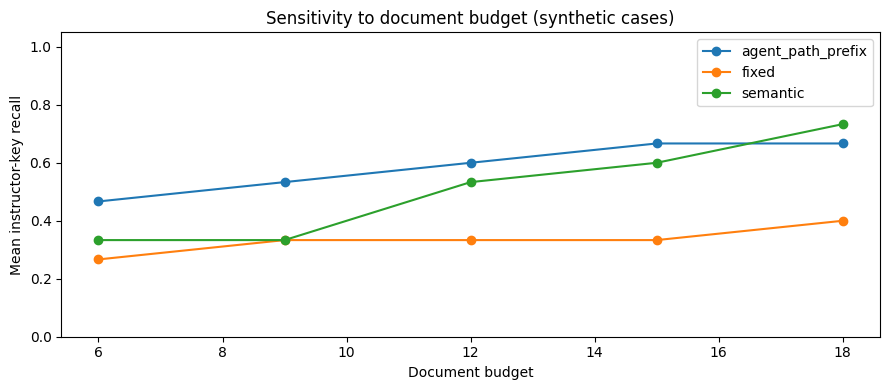

Agent values are prefixes of prior paths, not fresh budget-conditioned LLM runs.


In [ ]:
BUDGETS=[6,9,12,15,18]
sensitivity=[]
for name,case in CASES.items():
    for budget in BUDGETS:
        runs={'semantic':semantic_baseline(case['question'],budget),
              'fixed':fixed_baseline(case['question'],budget),
              'agent_path_prefix':{'visited':set(AGENT_RUNS[name]['path'][:budget])}}
        for method,run in runs.items():
            seen=run['visited']; target=set(case['critical_ids'])
            sensitivity.append({'case':name,'budget':budget,'method':method,
                'critical_recall':len(seen&target)/len(target),'documents':len(seen)})
SENSITIVITY=pd.DataFrame(sensitivity)
display(SENSITIVITY.groupby(['method','budget'],as_index=False).critical_recall.mean().round(3))
fig,ax=plt.subplots(figsize=(9,4))
for method,g in SENSITIVITY.groupby('method'):
    s=g.groupby('budget').critical_recall.mean()
    ax.plot(s.index,s.values,marker='o',label=method)
ax.set(xlabel='Document budget',ylabel='Mean instructor-key recall',ylim=(0,1.05),
 title='Sensitivity to document budget (synthetic cases)')
ax.legend();plt.tight_layout();plt.show()
print('Agent values are prefixes of prior paths, not fresh budget-conditioned LLM runs.')

## Cell 14 — Robustness, distractors and counterfactual evidence

A credible research agent must do more than follow conveniently connected documents. Legal questions routinely contain distractors: a document may use the right words while addressing the wrong procedure; an older rule may look relevant while having been superseded; an exception may reverse an apparently general proposition. To test the navigation architecture rather than merely illustrate it, this cell creates controlled counterfactual questions and measures whether retrieval and navigation remain anchored to the relevant legal issues.

We introduce three variants of the financing consultation. One adds an unrelated labor-law phrase; another emphasizes a customs issue; and a third stresses due process. The variants do not alter the vault. Instead, they test the sensitivity of the retrieval frontier to the wording of the user's question. This is an intentionally limited robustness check. It does not establish that an agent can resolve real legal ambiguity, and it does not ask the model to invent a legal rule. It simply shows how different issue formulations change the first-stage evidence candidates and their domain distribution.

The experiment also inspects the distribution of synthetic source-status flags in the top-ranked results. A retrieval method that places a superseded source near the top is not necessarily malfunctioning; obsolete material may be relevant to historical interpretation or to understanding a dispute. The error would be treating that source as currently controlling without verification. For that reason, we report retrieval and authority screening separately. The same distinction should be carried into the final memorandum: an agent may mention a superseded source as background while excluding it from positive legal support.

Students should look for two kinds of instability. The first is lexical sensitivity: small wording changes can shift the highest-ranked documents even when the underlying legal question remains similar. The second is cross-domain sensitivity: introducing a genuinely new fact should redirect the research into another layer of the graph. These are different phenomena and should not be conflated. A mature Level 3 system needs both stability against irrelevant noise and flexibility in response to material new evidence. The cell prepares the ground for later laboratories involving adversarial tests, agent disagreement and dynamic research planning.

In [ ]:
base=CASES['A_Financing']['question']
VARIANTS={
 'original':base,
 'irrelevant_labor_phrase':base+' An unrelated employment training brochure is attached.',
 'customs_fact_added':base+' Imported equipment may have been misclassified in customs declarations.',
 'due_process_emphasis':base+' The regulator may have denied an opportunity to respond.'}
robust=[]
for label,q in VARIANTS.items():
    found=semantic_search(q,12)
    counts=Counter(notes[r['id']]['domain'] for r in found)
    flags=Counter(authority_gate(r['id']) for r in found)
    robust.append({'variant':label,'top_5':[r['id'] for r in found[:5]],
       'domains_in_top_12':dict(counts),'authority_flags':dict(flags),
       'overlap_with_original_top_12':len({r['id'] for r in found}&
         {r['id'] for r in semantic_search(base,12)})})
ROBUSTNESS=pd.DataFrame(robust)
display(ROBUSTNESS)
print('Robustness concerns candidate retrieval; no legal applicability is inferred.')

,variant,top_5,domains_in_top_12,authority_flags,overlap_with_original_top_12
0,original,"[COM-013, SEC-013, COM-017, SEC-017, COM-037]","{'Commercial': 4, 'Securities': 3, 'Civil': 4,...","{'illustrative_only': 10, 'needs_applicability...",12
1,irrelevant_labor_phrase,"[COM-013, SEC-013, COM-017, SEC-017, COM-037]","{'Commercial': 4, 'Securities': 3, 'Civil': 4,...","{'illustrative_only': 10, 'needs_applicability...",12
2,customs_fact_added,"[COM-013, SEC-013, COM-017, SEC-017, COM-037]","{'Commercial': 4, 'Securities': 3, 'Civil': 4,...","{'illustrative_only': 10, 'needs_applicability...",12
3,due_process_emphasis,"[COM-013, SEC-013, COM-017, SEC-017, COM-037]","{'Commercial': 4, 'Securities': 3, 'Civil': 4,...","{'illustrative_only': 10, 'needs_applicability...",12


Robustness concerns candidate retrieval; no legal applicability is inferred.


## Cell 15 — Research dossier, reproducibility and handoff

The final laboratory cell transforms an experimental run into a reproducible research dossier. A professional legal research workflow should preserve not only its final narrative but also the provenance of the materials consulted, the decisions made along the way, the unresolved issues, and the conditions under which the research was conducted. This is especially important for an autonomous agent because the route through the knowledge graph may differ between executions, models and prompts. Without an audit record, a polished memorandum could conceal an incomplete or unrepeatable investigation.

The dossier produced here contains the synthetic case questions, metadata about the vault and graph, baseline and agent performance tables, research traces, stopping diagnostics, and the fictional legal memoranda. It records whether live Claude navigation was actually available. If the notebook ran in heuristic mode, the output explicitly says so. That distinction is essential: a deterministic fallback may demonstrate the software architecture, but it does not validate the LLM's autonomous judgment. The dossier also includes a clear warning that no source in the corpus is authentic Mexican law and that the results are not legal advice.

A small manifest captures the seed, model identifier, number of nodes, number of edges and names of the graph layers. These fields are not a complete reproducibility protocol; full production reproducibility would also require dependency versions, prompts, model versions, timestamps, source snapshots and secure retention of logs. Nevertheless, the manifest makes the classroom exercise inspectable and easy to extend. The resulting JSON can be downloaded from Colab and used in subsequent exercises on evaluation, supervision or multi-agent coordination.

The pedagogical conclusion is that an autonomous Second Brain is not simply an LLM wrapped around a search engine. It is a governed research process with state, actions, evidence, constraints and accountability. The ability to decide what to investigate next is the hallmark of Level 3; the ability to justify and reconstruct those decisions is what makes the system suitable for serious professional education. This final cell therefore treats documentation and auditability as part of the architecture itself, not as an optional reporting convenience.

### Researcher Perspective: Deep Dive into the Content of the Dossier (Cell 15)

The research **Dossier** acts as the final consolidated intelligence package of our autonomous investigation. It bridges the gap between raw, disconnected graph nodes discovered during exploration and an auditable, human-verifiable record.

Typically, a research dossier contains several structured layers of content:

#### 1. The Core Document Register
This lists every unique synthetic document visited during the path traversal, mapped directly to its Metadata:
* **Source Identifier**: The unique alphanumeric ID (e.g., `TAX-101`, `CON-204`).
* **Primary Domain**: The legal area (e.g., *Constitutional*, *Tax*, *Customs*, *Corporate*).
* **Thematic Tags**: Specific topic tags extracted from the node (e.g., *VAT Exemptions*, *Amparo Process*, *Import Duties*).

#### 2. The Verification and Integrity Audits
To satisfy the standards of a responsible autonomous system, the Dossier subjects each cited node to our strict **Authority Gates**:
* **Illustrative Status**: Notes that are current and active within our synthetic corpus, marked as safe for educational simulation.
* **Exception Warnings**: Flags indicating that a document is subject to narrow applicability rules or pending legal challenges (requiring immediate practitioner review).
* **Supersession Exclusions**: Notes that have been legally overtaken or invalidated by subsequent rulings. The Dossier explicitly quarantines these from supporting positive legal claims.

#### 3. Traceability and Citation Lineage
Unlike an unstructured summary, every claim in the Dossier must preserve its origin. It logs:
* The exact sequential step at which the document was acquired.
* Whether it was selected by **Claude** or a deterministic mathematical fallback.
* The explicit reason the model provided for its selection, ensuring that the entire decision-making chain remains completely transparent and auditable.

In [ ]:
from datetime import datetime, timezone
import csv, hashlib
RUN_DIR=OUTPUT_DIR/('run_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
RUN_DIR.mkdir(parents=True,exist_ok=True)
def safe_json(obj):
    if isinstance(obj,set): return sorted(obj)
    if isinstance(obj,(np.integer,np.floating)): return obj.item()
    if isinstance(obj,Path): return str(obj)
    raise TypeError(f'Unserializable type: {type(obj)}')
for name,run in AGENT_RUNS.items():
    (RUN_DIR/f'{name}_trace.json').write_text(json.dumps(run,default=safe_json,indent=2,ensure_ascii=False),encoding='utf-8')
    (RUN_DIR/f'{name}_memo.md').write_text(MEMOS[name],encoding='utf-8')
results.to_csv(RUN_DIR/'comparison.csv',index=False)
STOP_AUDITS.to_csv(RUN_DIR/'stopping_audit.csv',index=False)
SENSITIVITY.to_csv(RUN_DIR/'sensitivity.csv',index=False)
ROBUSTNESS.to_json(RUN_DIR/'robustness.json',orient='records',indent=2)
metadata={'topic':'791','synthetic':True,'seed':SEED,'model_requested':MODEL,
          'live_client_configured':CLAUDE_ENABLED,'root':str(ROOT_DIR),
          'document_count':len(notes),'graph_nodes':G.number_of_nodes(),
          'graph_edges':G.number_of_edges(),
          'run_modes':{name:r['mode'] for name,r in AGENT_RUNS.items()},
          'vault_sha256':hashlib.sha256(VAULT_JSON.read_bytes()).hexdigest()}
(RUN_DIR/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
assert len(list(VAULT_DIR.glob('*.md')))==350
assert all(set(run['path'])<=set(notes) for run in AGENT_RUNS.values())
print('Saved audit package:',RUN_DIR)
print('Obsidian vault:',VAULT_DIR)
print('Modes:',metadata['run_modes'])

Saved audit package: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/research_outputs/run_20261011T145206Z
Obsidian vault: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/vault
Modes: {'A_Financing': 'live_llm', 'B_Customs': 'live_llm', 'C_Acquisition': 'live_llm'}


## Cell 16 - The Capstone Memoranda




**Cell 16** represents the absolute pinnacle of this laboratory journey. Up to this point, students have configured state graphs, queried vectors, and guided an autonomous agent through iterative decision cycles. While those steps demonstrate architectural mechanics, Cell 16 delivers the **concrete final product**: a set of highly polished, professional-grade Legal Committee Memoranda.

Here is how Cell 16 converts raw computational paths into institutional-quality deliverables:

#### 1. From Research Trace to Legal Draft
The cell collects the full audit trail of the autonomous exploration (the exact sequence of visited documents, their domains, and validation flags) and feeds this structural evidence package to **Claude**. Under strict instructions, the model acts as a senior legal research drafting assistant. It synthesizes the evidence into a rigorous legal briefing that mimics the internal peer-review documents used in elite global firms.

#### 2. Strict Structural Validation and Enforcement
To prevent the common pitfalls of generative models, Cell 16 subjects the drafted memoranda to a deterministic **Validation Gate**:
* **Heading Compliance**: It ensures all seven required headings (such as *Synthetic Legal Framework*, *Risk Assessment*, and *Proposed Committee Resolution*) are explicitly present.
* **Citation Integrity**: It checks that every bracketed citation (e.g., `[TAX-101]`) matches a document actually inspected during the research path, instantly flagging any hallucinations.
* **Length & Disclaimer Constraints**: It verifies length parameters and mandates the prominent placement of the synthetic disclaimer.

#### 3. Professional Deliverables (PDF & Obsidian Handoff)
If the validation checks pass, the cell automatically compiles the individual markdown briefings into a **paginated, beautifully formatted PDF document** utilizing `reportlab`. Simultaneously, it exports the files with active internal wikilinks directly to the students' Obsidian vault, linking the research notes to the final analysis.

This cell demonstrates the ultimate objective of a Level 3 system: a governed, reliable workflow where the raw output of AI agency is compiled, validated, and translated into a high-stakes professional artifact.

In [ ]:
# CELL 16 — FULL SYNTHETIC LEGAL COMMITTEE MEMORANDA
# Requires Cells 1–15. Uses the configured ROOT_DIR, OUTPUT_DIR, VAULT_DIR,
# CASES, AGENT_RUNS, notes, MODEL and claude_client. Never downgrades MODEL.
from pathlib import Path
from datetime import datetime, timezone
import re, json, subprocess, sys, importlib.util

COMMITTEE_DIR = OUTPUT_DIR / 'committee_memoranda'
COMMITTEE_DIR.mkdir(parents=True, exist_ok=True)
OBSIDIAN_MEMO_DIR = VAULT_DIR / 'Research_Memoranda'
OBSIDIAN_MEMO_DIR.mkdir(parents=True, exist_ok=True)

# 400 words is the prior pedagogical target; committee writing can run longer.
TARGET_WORDS = 550
MIN_WORDS = 380
REQUIRED_HEADINGS = [
    'Question Presented', 'Facts and Assumptions', 'Synthetic Legal Framework',
    'Integrated Legal Analysis', 'Risk Assessment',
    'Open Questions and Human Verification', 'Proposed Committee Resolution'
]
DISCLAIMER = ('FICTIONAL TRAINING MATERIAL — SYNTHETIC LEGAL AUTHORITIES ONLY. '
              'NOT AN OPINION ON MEXICAN LAW. NOT FOR CLIENT OR COMMITTEE RELIANCE.')

def evidence_package(case_name):
    case, run = CASES[case_name], AGENT_RUNS[case_name]
    visited = list(dict.fromkeys(run['path']))
    assert set(visited) <= set(notes), 'Research trace contains unknown source IDs'
    return {
        'case_name': case_name,
        'question': case['question'],
        'method': run['mode'],
        'stop_reason': run.get('stop_reason', 'not recorded'),
        'inspected_count': len(visited),
        'evidence': [{
            'id': nid, 'domain': notes[nid]['domain'],
            'type': notes[nid]['type'], 'status': notes[nid]['status'],
            'topics': notes[nid]['topics'], 'text': notes[nid]['text']
        } for nid in visited],
        'trace': run.get('trace', [])[-12:]
        # Instructor keys (case['critical_ids']) deliberately excluded.
    }

def extract_text(message):
    return '\n'.join(part.text for part in message.content
                     if getattr(part, 'type', None) == 'text' and getattr(part, 'text', None))

def draft_committee_memo(package):
    if not CLAUDE_ENABLED or claude_client is None:
        return None, 'Claude client unavailable; no LLM memo generated'
    system = f"""You are a senior legal research drafting assistant preparing a FICTIONAL
training memorandum for an internal law-firm committee. The corpus is invented,
not Mexican legislation or real jurisprudence. Do not assert any synthetic
provision is actual Mexican law. Do not invent facts, court holdings, statute
numbers, deadlines, procedural requirements, or external legal sources.
Write polished, sober, analytically rigorous English, approximately
{TARGET_WORDS} words (acceptable 380–800). Use exactly these Markdown headings:
{chr(10).join('## ' + h for h in REQUIRED_HEADINGS)}
Include at least three substantive paragraphs in Integrated Legal Analysis.
Distinguish fact, inference, possibility, and unresolved question.
Assess cross-domain interactions and source status (including superseded and
exception-sensitive flags) without assuming applicability. Cite only evidence
IDs supplied in the input, in form [COM-001]. Cite at least three distinct
visited IDs when available; never fabricate an ID. If evidence is inadequate,
say so. In the resolution specify conditional next steps, requested documents,
and the need for verification against official current Mexican sources.
Begin with this exact disclaimer: {DISCLAIMER}
Output ONLY the completed Markdown memorandum; no code fences."""
    try:
        response = claude_client.messages.create(
            model=MODEL, max_tokens=2600, system=system,
            messages=[{'role': 'user', 'content': json.dumps(package, ensure_ascii=False)}]
        )
        text = extract_text(response).strip()
        if getattr(response, 'stop_reason', None) == 'max_tokens':
            return text, 'Model output truncated (max_tokens)'
        return text, None
    except Exception as exc:
        return None, f'{type(exc).__name__}: {str(exc)[:240]}'

def validate_committee_memo(text, package):
    if not text:
        return {'approved_for_training': False, 'errors': ['No model-authored text'],
                'word_count': 0, 'cited_ids': []}
    allowed = {e['id'] for e in package['evidence']}
    cited = set(re.findall(r'\[([A-Z]{3}-\d{3})\]', text))
    headings = set(re.findall(r'^##\s+(.+?)\s*$', text, flags=re.M))
    missing = [h for h in REQUIRED_HEADINGS if h not in headings]
    word_count = len(re.findall(r"\b[\w'-]+\b", text))
    errors = []
    if not text.startswith(DISCLAIMER): errors.append('Exact synthetic disclaimer missing')
    if missing: errors.append('Missing headings: ' + ', '.join(missing))
    if cited - allowed: errors.append('Unvisited citations: ' + ', '.join(sorted(cited-allowed)))
    if len(cited) < min(3, len(allowed)): errors.append('Insufficient distinct evidence citations')
    if word_count < MIN_WORDS: errors.append(f'Underlength: {word_count} words')
    if word_count > 900: errors.append(f'Overlength: {word_count} words')
    return {'approved_for_training': not errors, 'errors': errors,
            'word_count': word_count, 'cited_ids': sorted(cited),
            'inspected_ids': sorted(allowed), 'missing_headings': missing}

def evidence_only_brief(package, failure):
    lines = [DISCLAIMER, '', '# EVIDENCE-ONLY BRIEF — NOT A CLAUDE LEGAL MEMORANDUM',
             '', f"**Case:** {package['case_name']}",
             f"**Consultation:** {package['question']}",
             f"**Drafting unavailable:** {failure}",
             '', '## Inspected fictional sources']
    for e in package['evidence']:
        lines.append(f"- [{e['id']}] {e['domain']} — {', '.join(e['topics'])}; status: {e['status']}")
    lines += ['', '## Required next step',
              'Enable and validate the selected Claude model, rerun Cell 16, '
              'and require lawyer review before any committee discussion.']
    return '\n'.join(lines) + '\n'

COMMITTEE_RESULTS = {}
for case_name in CASES:
    pkg = evidence_package(case_name)
    draft, failure = draft_committee_memo(pkg)
    check = validate_committee_memo(draft, pkg)
    if failure: check['errors'].append(failure)
    accepted = bool(draft) and not failure and check['approved_for_training']
    status = 'DRAFT_FOR_HUMAN_REVIEW' if accepted else 'REVIEW_REQUIRED'
    content = draft if draft else evidence_only_brief(pkg, failure or 'No draft returned')
    # Always show validation status; never imply committee approval.
    content = f'**STATUS: {status} — SYNTHETIC TRAINING ONLY**\n\n' + content
    stem = case_name.upper() + '_COMMITTEE_MEMORANDUM'
    path = COMMITTEE_DIR / (stem + '.md')
    path.write_text(content + '\n', encoding='utf-8')
    # In Obsidian, wikilinks are added only for verified visited citations.
    wikilinked = re.sub(r'\[([A-Z]{3}-\d{3})\]',
                        lambda m: f'[[{m.group(1)}]]' if m.group(1) in check['inspected_ids']
                        else m.group(0), content)
    (OBSIDIAN_MEMO_DIR / (stem + '.md')).write_text(wikilinked + '\n', encoding='utf-8')
    COMMITTEE_RESULTS[case_name] = {'status': status, 'text': content,
                                     'path': str(path), 'validation': check,
                                     'model_requested': MODEL, 'api_failure': failure,
                                     'research_mode': pkg['method']}
    (COMMITTEE_DIR / (stem + '_VALIDATION.json')).write_text(
        json.dumps({k:v for k,v in COMMITTEE_RESULTS[case_name].items() if k!='text'},
                   ensure_ascii=False, indent=2), encoding='utf-8')

# A professionally formatted, paginated combined PDF; synthetic disclaimer repeated.
if importlib.util.find_spec('reportlab') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'reportlab'])
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, PageBreak, KeepTogether
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_LEFT
from reportlab.lib import colors
from reportlab.lib.units import inch
from xml.sax.saxutils import escape
pdf_path = COMMITTEE_DIR / 'TOPIC_791_SYNTHETIC_COMMITTEE_MEMORANDA.pdf'
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name='MemoTitle791', parent=styles['Heading1'],
                          fontName='Helvetica-Bold', fontSize=15, leading=20,
                          textColor=colors.HexColor('#17324D'), spaceAfter=14))
styles.add(ParagraphStyle(name='MemoHead791', parent=styles['Heading2'],
                          fontName='Helvetica-Bold', fontSize=10.5, leading=15,
                          textColor=colors.HexColor('#176C75'), spaceBefore=13, spaceAfter=6))
styles.add(ParagraphStyle(name='MemoBody791', parent=styles['BodyText'],
                          fontName='Helvetica', fontSize=9.5, leading=15,
                          spaceAfter=9, alignment=TA_LEFT))
styles.add(ParagraphStyle(name='MemoWarn791', parent=styles['BodyText'],
                          fontName='Helvetica-Bold', fontSize=8, leading=12,
                          textColor=colors.HexColor('#8A3329'), spaceAfter=10))
story = []
for idx, (case_name, item) in enumerate(COMMITTEE_RESULTS.items()):
    if idx: story.append(PageBreak())
    story.append(Paragraph('TOPIC 791 | ' + escape(case_name.replace('_',' ')), styles['MemoTitle791']))
    story.append(Paragraph(escape(DISCLAIMER), styles['MemoWarn791']))
    story.append(Paragraph(escape('STATUS: '+item['status']+' | MODEL: '+item['model_requested']), styles['MemoWarn791']))
    for line in item['text'].splitlines():
        line = line.strip()
        if not line or line.startswith('**STATUS:') or line == DISCLAIMER: continue
        if line.startswith('## '):
            story.append(Paragraph(escape(line[3:]), styles['MemoHead791']))
        elif line.startswith('# '):
            story.append(Paragraph(escape(line[2:]), styles['MemoTitle791']))
        elif line.startswith('- '):
            story.append(Paragraph('&#8226; ' + escape(line[2:]), styles['MemoBody791']))
        else:
            story.append(Paragraph(escape(line).replace('**',''), styles['MemoBody791']))

def footer(canvas, doc):
    canvas.saveState()
    canvas.setFont('Helvetica', 7)
    canvas.setFillColor(colors.HexColor('#7B8790'))
    canvas.drawString(0.72*inch, 0.48*inch, 'TOPIC 791 | FICTIONAL TRAINING ONLY — NOT MEXICAN LEGAL ADVICE')
    canvas.drawRightString(7.75*inch, 0.48*inch, str(doc.page))
    canvas.restoreState()
SimpleDocTemplate(str(pdf_path), pagesize=(8.5*inch,11*inch),
                  rightMargin=.78*inch, leftMargin=.78*inch,
                  topMargin=.78*inch, bottomMargin=.82*inch,
                  title='TOPIC 791 — Synthetic Legal Committee Memoranda').build(
                      story, onFirstPage=footer, onLaterPages=footer)

summary = [{ 'case': k, 'status': v['status'], 'words': v['validation']['word_count'],
             'citations': len(v['validation']['cited_ids']),
             'validation_errors': '; '.join(v['validation']['errors'])[:120] }
           for k,v in COMMITTEE_RESULTS.items()]
print('Model requested:', MODEL)
print('Markdown and validation:', COMMITTEE_DIR)
print('Obsidian notes:', OBSIDIAN_MEMO_DIR)
print('Combined PDF:', pdf_path)
display(pd.DataFrame(summary))

Model requested: claude-haiku-5-5
Markdown and validation: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/research_outputs/committee_memoranda
Obsidian notes: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/vault/Research_Memoranda
Combined PDF: /content/drive/MyDrive/Colab Notebooks/TOPIC_791 THE LEGAL SECOND BRAIN/research_outputs/committee_memoranda/TOPIC_791_SYNTHETIC_COMMITTEE_MEMORANDA.pdf


,case,status,words,citations,validation_errors
0,A_Financing,DRAFT_FOR_HUMAN_REVIEW,735,14,
1,B_Customs,REVIEW_REQUIRED,616,18,Missing headings: Open Questions and Human Ver...
2,C_Acquisition,REVIEW_REQUIRED,73,0,"Missing headings: Synthetic Legal Framework, I..."


## Conclusion — the autonomous Second Brain as an evidence-acquisition system

This laboratory has moved from a vault that can answer questions to a vault that supports a governed research process. The distinction is the core pedagogical result. Semantic retrieval supplies initial relevance; graph structure supplies discoverable relationships; an autonomous navigation policy decides which relationship deserves attention next. The decision is not made in a vacuum. It depends on the original consultation, the evidence already collected, the candidate frontier, unresolved issues, and the remaining budget. In that sense, navigation is endogenous to the evolving research state.

The Mexican civil-law setting makes this distinction particularly instructive. A legal consultation is not solved by accumulating superficially similar documents. A researcher must ask which sources are authoritative, which provisions apply to the facts, which institutions have competence, whether exceptions or procedural constraints intervene, and whether judicial interpretations alter the analysis. The synthetic vault models these categories without pretending to reproduce real Mexican law. Its documents are fictional, its connections are illustrative, and its instructor keys are retrieval targets rather than expert legal opinions. These limitations are not incidental: they make the classroom experiment safe, inspectable, and reproducible.

The five graph layers provide a structured way to represent different reasons for moving from one note to another. Hierarchy is not the same as substantive overlap; procedure is not the same as judicial interpretation; cross-border connections raise questions distinct from purely domestic contractual obligations. By retaining edge types, the system can explain why a document entered the candidate frontier. The agent then chooses among candidates rather than being forced to traverse every edge or stop at a predetermined depth. This is a practical form of bounded autonomy: the model chooses the next research action, while Python validates its admissibility and records the outcome.

The distinction between autonomous decisions and deterministic fallback deserves particular emphasis. A live model may be unavailable, produce malformed JSON, or request an invalid node. A robust system must recover, but it must also disclose what happened. The notebook's audit trail labels every decision source. A fallback may keep the exercise running, yet it does not demonstrate model judgment. Likewise, a model's stated reason for visiting a document is useful evidence of its declared plan, not direct access to its internal reasoning. What we can verify is the action, the source retrieved, the change in the evidence state, and the stopping condition.

The three-way comparison encourages a disciplined attitude toward innovation. Autonomous navigation should not be celebrated simply because it appears more sophisticated. It should be judged against semantic retrieval and deterministic graph traversal on comparable budgets. The synthetic benchmark records key-source recall, domain coverage, document count, and model calls. It can reveal that autonomy discovers neglected domains; it can also reveal inefficient wandering, overattention to highly connected hubs, or premature stopping. No single score proves legal correctness. The final memorandum therefore emphasizes evidence provenance, missing facts, and uncertainty instead of claiming definitive answers.

A larger production system would require controls not implemented here: authoritative official source ingestion, temporal versioning, jurisdiction-aware citation checking, human review, confidentiality safeguards, secure tool permissions, and expert validation of legal conclusions. The synthetic exercise should be understood as a research architecture prototype. It demonstrates how to coordinate semantic indexes, multiplex graphs, tool-constrained model decisions, and auditable state transitions in a single Colab notebook. It does not authorize reliance on generated legal propositions.

The deeper lesson extends beyond law. In finance, medicine, policy, and corporate strategy, an intelligent assistant may fail not because it cannot summarize what it has seen, but because it does not know what evidence it still lacks. Level 3 reframes the Second Brain as an evidence-acquisition system capable of revising its own research trajectory. The next pedagogical frontier is not merely more documents or more links. It is the disciplined orchestration of several specialized investigators that can test one another's assumptions while preserving a common evidence ledger and governance layer. Before moving to that stage, this notebook gives students a complete, observable single-agent foundation: a vault, five graphs, a seed, an adaptive loop, an audit trail, and a measurable comparison of research policies.

**Final principle:** An autonomous Second Brain does not merely retrieve what it knows. It makes a governed decision about what it needs to know next.

### Selected methodological references

1. Constitución Política de los Estados Unidos Mexicanos (consult official current text for real practice; not reproduced in the synthetic corpus).
2. Suprema Corte de Justicia de la Nación, *Semanario Judicial de la Federación* (official jurisprudence source; not ingested).
3. Cámara de Diputados, *Leyes Federales Vigentes* (official legislative source; not ingested).
4. Lewis et al. (2020), Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.
5. Yao et al. (2023), ReAct: Synergizing Reasoning and Acting in Language Models.
6. Schick et al. (2023), Toolformer: Language Models Can Teach Themselves to Use Tools.
7. Edge et al. (2024), From Local to Global: A Graph RAG Approach to Query-Focused Summarization.
8. Wu et al. (2023), AutoGen: Enabling Next-Gen LLM Applications via Multi-Agent Conversation.
9. Guo et al. (2024), Large Language Model Based Multi-Agents: A Survey of Progress and Challenges.
10. NIST (2023), AI Risk Management Framework 1.0.
11. NIST (2024), Generative Artificial Intelligence Profile.
12. OECD (2019, updated 2024), OECD AI Principles.
13. Ashley (2017), *Artificial Intelligence and Legal Analytics*.
14. Surden (2019), Artificial Intelligence and Law: An Overview.
15. Bommarito and Katz (2017), A Mathematical Approach to the Study of the United States Code.

*References are methodological orientation only; the laboratory does not claim to have verified current versions of legal authorities.*